# Лабораторная работа №1
## Системы искусственного интеллекта и машинное обучение

**Тема:** Линейная регрессия и факторный анализ

**Студент:** Косяченко Даниил Алексеевич

**Группа:** АВТ-313

## 1. Введение

**Цель работы:** изучение основ линейной регрессии и методов регуляризации, построение
регрессионных моделей на реальных данных и оценка их качества, а также исследование
мультиколлинеарности признаков и её устранение методом главных компонент.

**Постановка задачи:**

Провести обучение моделей линейной регрессии на датасете с Kaggle:

1. Загрузить датасет из репозитория (kaggle.com).
2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков
   и целевой переменной.
3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные
   переменные.
4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчёт
   VIF-коэффициента).
5. Построить регрессионные модели (линейная, лассо и гребневая). Разделить данные на
   тренировочную и тестовую выборки (80/20). Использовать кросс-валидацию. Оценить качество
   моделей с помощью метрик RMSE (Root Mean Square Error), R² (коэффициент детерминации)
   и MAPE (Mean Absolute Percentage Error).
6. Построить график остатков моделей (с горизонтальной линией на уровне 0) и исследовать
   структуру остатков на предмет гомоскедастичности или гетероскедастичности.
7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных
   компонент (PCA). Перед проведением PCA провести стандартизацию данных.
8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), используя в качестве признаков
   главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных
   на исходных данных и на главных компонентах.

## 2. Описание датасета

Используется датасет **Students Performance in Exams** (`StudentsPerformance.csv`) с Kaggle.
В нём представлены результаты экзаменов 1 000 школьников и сведения о них. Столбцы:

1. `gender` — пол ученика (`female` / `male`);
2. `race/ethnicity` — этническая группа (анонимизирована: `group A` … `group E`);
3. `parental level of education` — уровень образования родителей (от `some high school` —
   неоконченная школа — до `master's degree` — магистратура);
4. `lunch` — тип школьного питания: `standard` (обычное) или `free/reduced` (бесплатное
   или льготное). Это косвенный показатель достатка семьи;
5. `test preparation course` — прошёл ли ученик подготовительный курс (`completed` / `none`);
6. `math score` — балл за экзамен по математике, 0–100 (**целевая переменная**);
7. `reading score` — балл за экзамен по чтению, 0–100;
8. `writing score` — балл за экзамен по письму, 0–100.

Целевая переменная — балл по математике. Она непрерывная, поэтому задача решается методами
регрессии.

**Задача:** предсказать результат по математике, зная результаты остальных экзаменов и сведения
об ученике.

Загрузка данных:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("StudentsPerformance.csv")
df.columns = ["gender", "race", "parent_edu", "lunch", "prep", "math", "reading", "writing"]
df.head(10)

Файл прочитан функцией `pd.read_csv()`, для удобства столбцам даны короткие имена. В таблице
1 000 строк и 8 столбцов:

- 3 числовых — баллы `math`, `reading`, `writing`;
- 5 категориальных — `gender`, `race`, `parent_edu`, `lunch`, `prep`.

Основные характеристики баллов (функция `df.describe()`):

| | math | reading | writing |
|---|---|---|---|
| среднее | 66.1 | 69.2 | 68.1 |
| стандартное отклонение | 15.2 | 14.6 | 15.2 |
| минимум | 0 | 17 | 10 |
| медиана | 66 | 70 | 69 |
| максимум | 100 | 100 | 100 |

Средние баллы по трём экзаменам близки (66–69), разброс одинаковый (~15 баллов). Минимальный
балл по математике — 0. Это аномально низкое значение, и ниже оно рассматривается как выброс.

Распределение баллов (целевая переменная — `math score`):

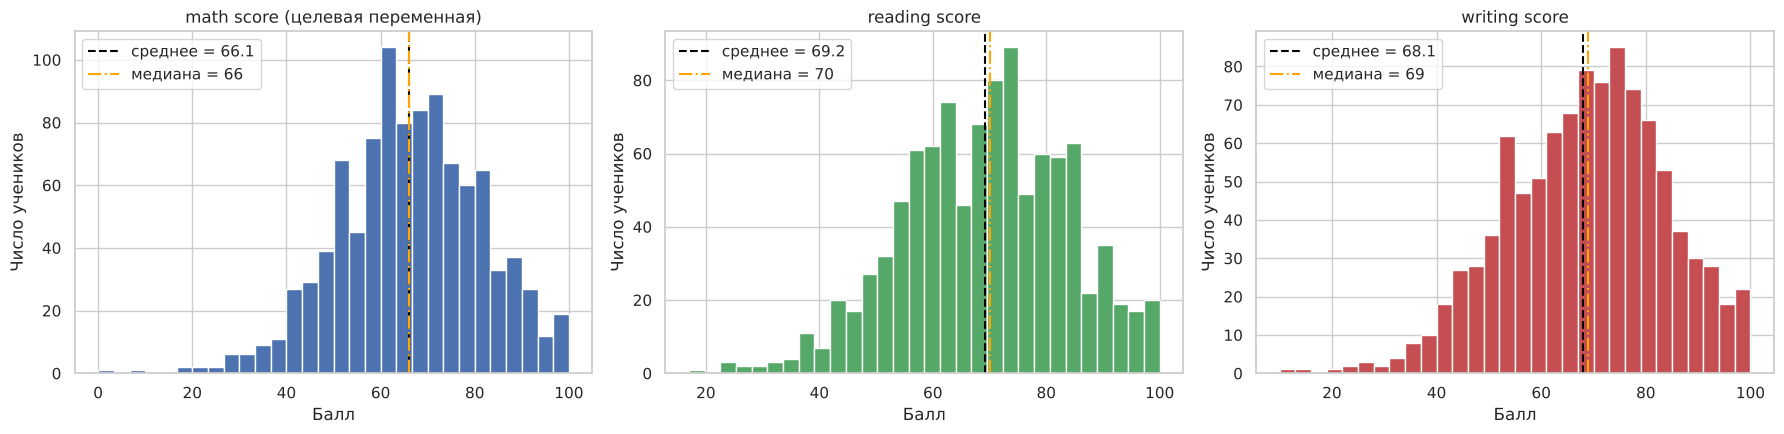

*Рисунок 1 — распределение баллов за три экзамена*

- Все три распределения **близки к нормальному**: колоколообразные, среднее почти совпадает
  с медианой.
- Асимметрия слабая и отрицательная: −0.28 у математики, −0.26 у чтения, −0.29 у письма.
  Левый хвост чуть длиннее: несколько учеников получили очень низкие баллы (до 0–20), тогда как
  сверху баллы ограничены значением 100.
- У каждого экзамена есть небольшое число учеников с максимальным баллом 100.

Распределение целевой переменной не требует преобразования (логарифмирования). Модель
предсказывает балл напрямую, ошибки интерпретируются в баллах.

Распределение категориальных признаков:

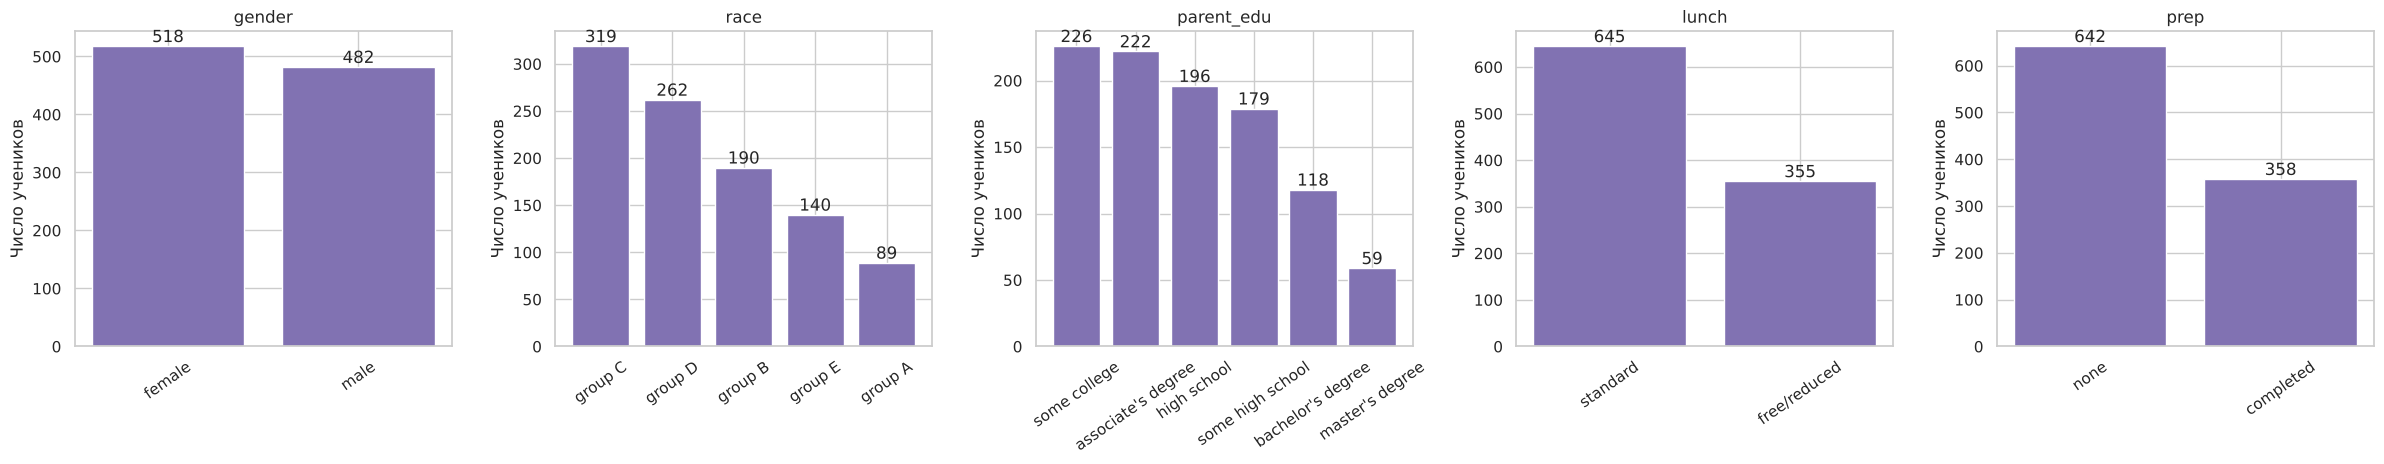

*Рисунок 2 — распределение категориальных признаков*

- **Пол** сбалансирован: 518 девушек и 482 юноши.
- **Этнические группы** представлены неравномерно: больше всего учеников в группе C (319),
  меньше всего — в группе A (89).
- **Образование родителей:** чаще всего встречаются `some college` (226) и `associate's degree`
  (222); магистратура — у родителей лишь 59 учеников.
- **Питание:** у 645 учеников обычное, у 355 (35.5%) — бесплатное или льготное.
- **Подготовительный курс** прошли 358 учеников (35.8%).

Все категории содержат не менее 59 наблюдений, поэтому коэффициенты при них будут оценены
надёжно.

### Зависимость целевого признака от независимых переменных

Зависимость балла по математике от остальных признаков проверена двумя способами.
Визуально — диаграммами рассеяния для числовых признаков и ящичными диаграммами для
категориальных. Количественно — корреляционным анализом.

Связь баллов между собой:

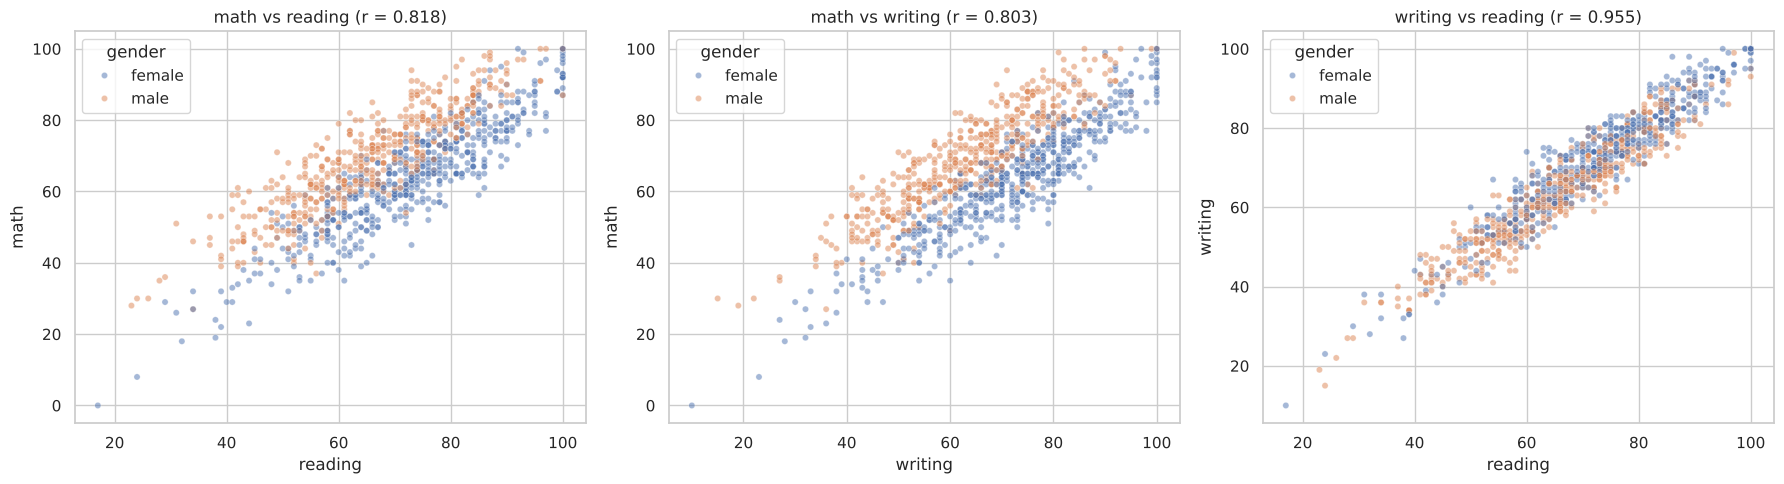

*Рисунок 3 — попарная связь баллов, цвет — пол ученика*

- **Чтение и письмо связаны почти линейно (r = 0.955)**: точки лежат в узкой полосе вдоль
  диагонали. Ученик, хорошо читающий, почти всегда хорошо пишет. Два этих признака несут
  практически одну и ту же информацию — **это источник мультиколлинеарности**.
- **Математика связана с чтением (r = 0.818) и письмом (r = 0.803)** слабее: облака точек шире.
- **Важное наблюдение — пол.** На графиках «math vs reading» и «math vs writing» точки юношей
  (оранжевые) систематически лежат **выше** точек девушек (синие). При одинаковом балле за чтение
  или письмо юноши получают по математике больше. На графике «writing vs reading» оба пола
  перемешаны.

Значит, пол — важный признак, причём его влияние проявляется только **вместе** с баллами
по языку.

Балл по математике в разрезе категориальных признаков:

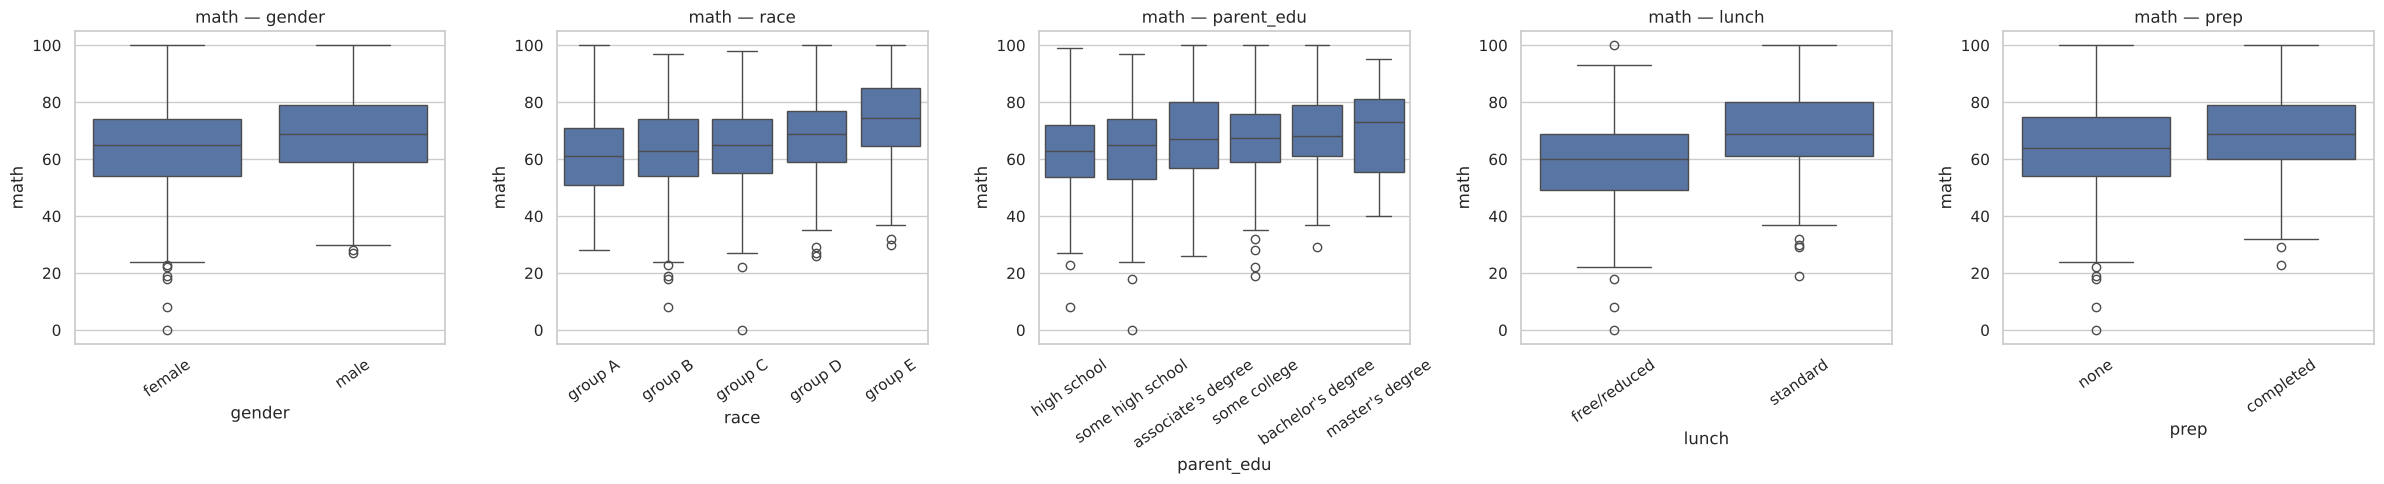

*Рисунок 4 — балл по математике в разрезе категориальных признаков*

| Признак | Группы и средний балл по математике |
|---|---|
| пол | девушки 63.6, юноши 68.7 |
| этническая группа | A 61.6, B 63.5, C 64.5, D 67.4, E 73.8 |
| образование родителей | high school 62.1 … master's degree 69.7 |
| питание | free/reduced 58.9, standard 70.0 |
| подготовительный курс | none 64.1, completed 69.7 |

- **Сильнее всего на балл влияет тип питания**: у учеников с обычным питанием балл выше на
  11 пунктов. Питание — показатель достатка семьи, а он влияет на условия обучения.
- **Подготовительный курс** даёт +5.6 балла, а этническая группа E выделяется заметно более
  высоким результатом.
- **Образование родителей** влияет умеренно: дети родителей со школьным образованием набирают
  ~62–63 балла, с высшим — ~69–70.
- **Юноши** в среднем на 5 баллов лучше по математике, но **хуже по чтению и письму**:
  65.5 и 63.3 против 72.6 и 72.5 у девушек.

Корреляционная матрица исходных признаков (бинарные признаки закодированы 0/1):

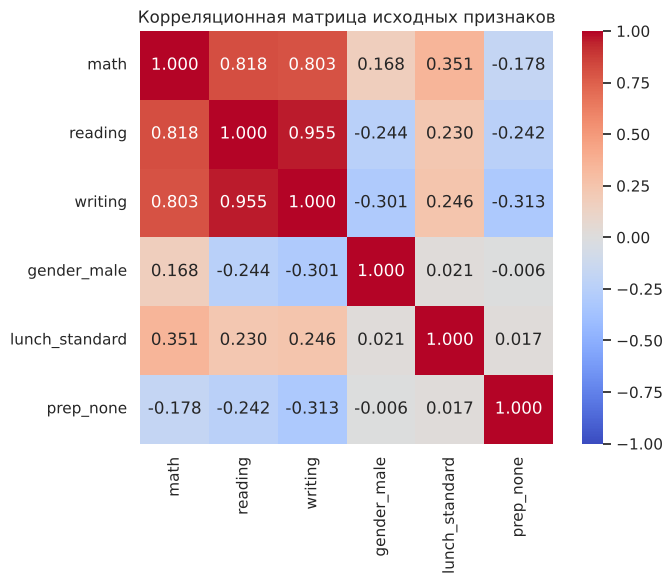

*Рисунок 5 — корреляционная матрица исходных признаков*

- **С баллом по математике** сильнее всего связаны чтение (0.818) и письмо (0.803), затем
  тип питания (0.351), отсутствие подготовительного курса (−0.178) и пол (0.168).
- **Между признаками** выделяется одна очень сильная связь: **чтение ↔ письмо (0.955)**.
  Остальные корреляции слабые, не более 0.31 по модулю.
- **Пол коррелирует с баллами по-разному:** положительно с математикой (+0.168), отрицательно
  с чтением (−0.244) и письмом (−0.301).
- **Подготовительный курс** сильнее связан с письмом (−0.313 для `prep_none`), чем с
  математикой (−0.178).

Эти разнонаправленные связи важны для интерпретации коэффициентов регрессии (раздел 4.2).

## 3. Подготовка данных

Для загрузки и подготовки данных использованы стандартные библиотеки Python:

- `pandas` — чтение CSV, проверка пропусков и дубликатов, One-Hot кодирование;
- `numpy` — вычисления;
- `scikit-learn` — разделение выборки (`train_test_split`) и нормализация (`StandardScaler`).

Проверка пропущенных значений выполнена функцией `df.isnull().sum()`, проверка дубликатов —
функцией `df.duplicated()`:

In [ ]:
print("Пропусков:", df.isnull().sum().sum())
print("Дубликатов:", df.duplicated().sum())

**Пропусков и дубликатов в датасете нет.** Удалять или заполнять ничего не требуется,
все 1 000 записей пригодны для анализа.

Проверка выбросов в баллах по правилу 1.5·IQR (за выброс считается значение вне интервала
$[Q_1 - 1.5\cdot IQR;\ Q_3 + 1.5\cdot IQR]$):

In [ ]:
for col in ["math", "reading", "writing"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, "граница:", q1 - 1.5 * iqr, "выбросы:", sorted(out[col].tolist()))

q1, q3 = df["math"].quantile([0.25, 0.75])
low = q1 - 1.5 * (q3 - q1)
df = df[df["math"] >= low].reset_index(drop=True)
print("Осталось строк:", len(df))

Выбросы только **снизу**: верхние границы (107–111 баллов) выше максимально возможного балла.

| Экзамен | Нижняя граница | Выбросы |
|---|---|---|
| math | 27.0 | 8 учеников: 0, 8, 18, 19, 22, 23, 24, 26 |
| reading | 29.0 | 6 учеников |
| writing | 25.9 | 5 учеников |

**Удалены 8 выбросов целевой переменной** (балл по математике ниже 27).

- Это крайне нетипичные результаты. Например, балл 0 при 17 за чтение и 10 за письмо, скорее
  всего, означает, что ученик фактически не писал экзамен.
- Такие значения сильно влияют на МНК-оценки.
- Кроме того, **нулевой балл делает метрику MAPE неопределённой**: при $y_i = 0$ деление
  на ноль даёт бесконечную ошибку.

Выбросы в чтении и письме — это признаки, а не целевая переменная. Отдельно они не удалялись:
два из них совпадают с выбросами по математике и ушли вместе с ними.

После удаления в выборке **992 ученика**.

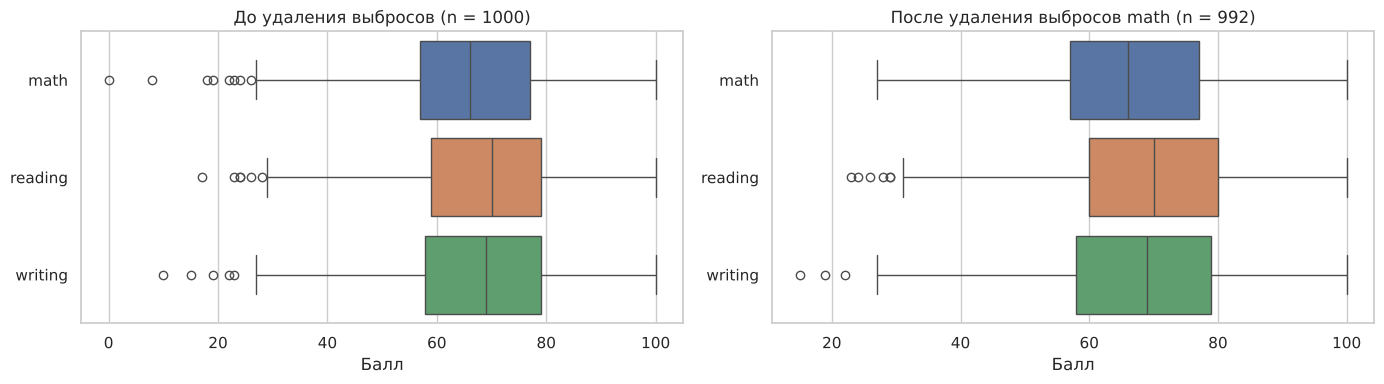

*Рисунок 6 — баллы до и после удаления выбросов целевой переменной*

На ящичных диаграммах после удаления исчезли крайние точки у математики (0–26 баллов).
У чтения и письма осталось по 3–4 умеренно низких значения. Это реальные слабые результаты,
согласованные с баллом по математике, поэтому они сохранены.

Категориальные переменные закодированы методом **One-Hot Encoding**:

In [ ]:
data = pd.get_dummies(df, columns=["gender", "race", "parent_edu", "lunch", "prep"],
                      drop_first=True, dtype=int)
X = data.drop(columns="math")
y = data["math"]
print(X.shape)
print(list(X.columns))

Получено **14 признаков**: 2 балла (`reading`, `writing`) и 12 индикаторов.

| Признак | Индикаторы | Базовая категория |
|---|---|---|
| пол | `gender_male` | female |
| этническая группа | `race_B`…`race_E` | group A |
| образование родителей | `parent_bachelor`, `parent_high_school`, `parent_master`, `parent_some_college`, `parent_some_high_school` | associate's degree |
| питание | `lunch_standard` | free/reduced |
| подготовительный курс | `prep_none` | completed |

В итоговой программе (раздел 7) индикаторы переименованы в короткие имена, указанные в таблице.

Параметр `drop_first=True` удаляет индикатор базовой категории. Это защищает от «ловушки
фиктивных переменных»: иначе сумма индикаторов одного признака всегда равнялась бы 1,
то есть константе. Возникла бы точная мультиколлинеарность, и коэффициенты нельзя было бы
оценить.

Для оценки качества моделей данные разделены в пропорции 80/20 (80% для обучения,
20% для тестирования):

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)
print("Средний балл:", round(y_train.mean(), 2), round(y_test.mean(), 2))

В обучающую выборку попало **793** ученика, в тестовую — **199**. Средний балл по математике
в выборках близок: 66.7 и 65.7. Значит, тестовая выборка репрезентативна.

Тестовая выборка используется только один раз — для итоговой оценки моделей. Гиперпараметры
подбираются кросс-валидацией внутри обучающей выборки.

**Признаки сильно различаются по масштабу.** Баллы `reading` и `writing` лежат в диапазоне
0–100 со стандартным отклонением ~15, а индикаторы принимают значения 0/1 со стандартным
отклонением 0.3–0.5. Поэтому нормализация обязательна.

Использована **стандартизация**: данные приведены к нулевому среднему значению и единичной
дисперсии, $z = (x - \mu)/\sigma$. Альтернатива — Min-Max scaling $(x - x_{min})/(x_{max} - x_{min})$,
приводящая признаки к отрезку [0; 1]. Сравнение обоих способов приведено в разделе 4.6.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.mean(axis=0).round(3))
print(X_train_scaled.std(axis=0).round(3))

После стандартизации каждый признак обучающей выборки имеет среднее 0 и стандартное
отклонение 1.

Параметры $\mu$ и $\sigma$ вычисляются **только по обучающей выборке** (`fit_transform`),
а тестовая выборка преобразуется теми же параметрами (`transform`). Это исключает утечку
информации из теста.

Стандартизация необходима по двум причинам:

- **Для Lasso и Ridge.** Штраф накладывается на величину коэффициентов, а баллы (0–100)
  и индикаторы (0/1) имеют разный масштаб.
- **Для PCA.** Иначе первые компоненты определялись бы баллами — признаками с наибольшей
  дисперсией.

Ещё одно преимущество: коэффициенты при стандартизованных признаках можно сравнивать между собой.
В итоговой программе стандартизация встроена в конвейер (`Pipeline`) и при кросс-валидации
переобучается на каждом фолде.

## 4. Ход работы

### 4.1 Корреляционный анализ и мультиколлинеарность

После кодирования признаков построены матрица корреляций и график VIF-коэффициентов.

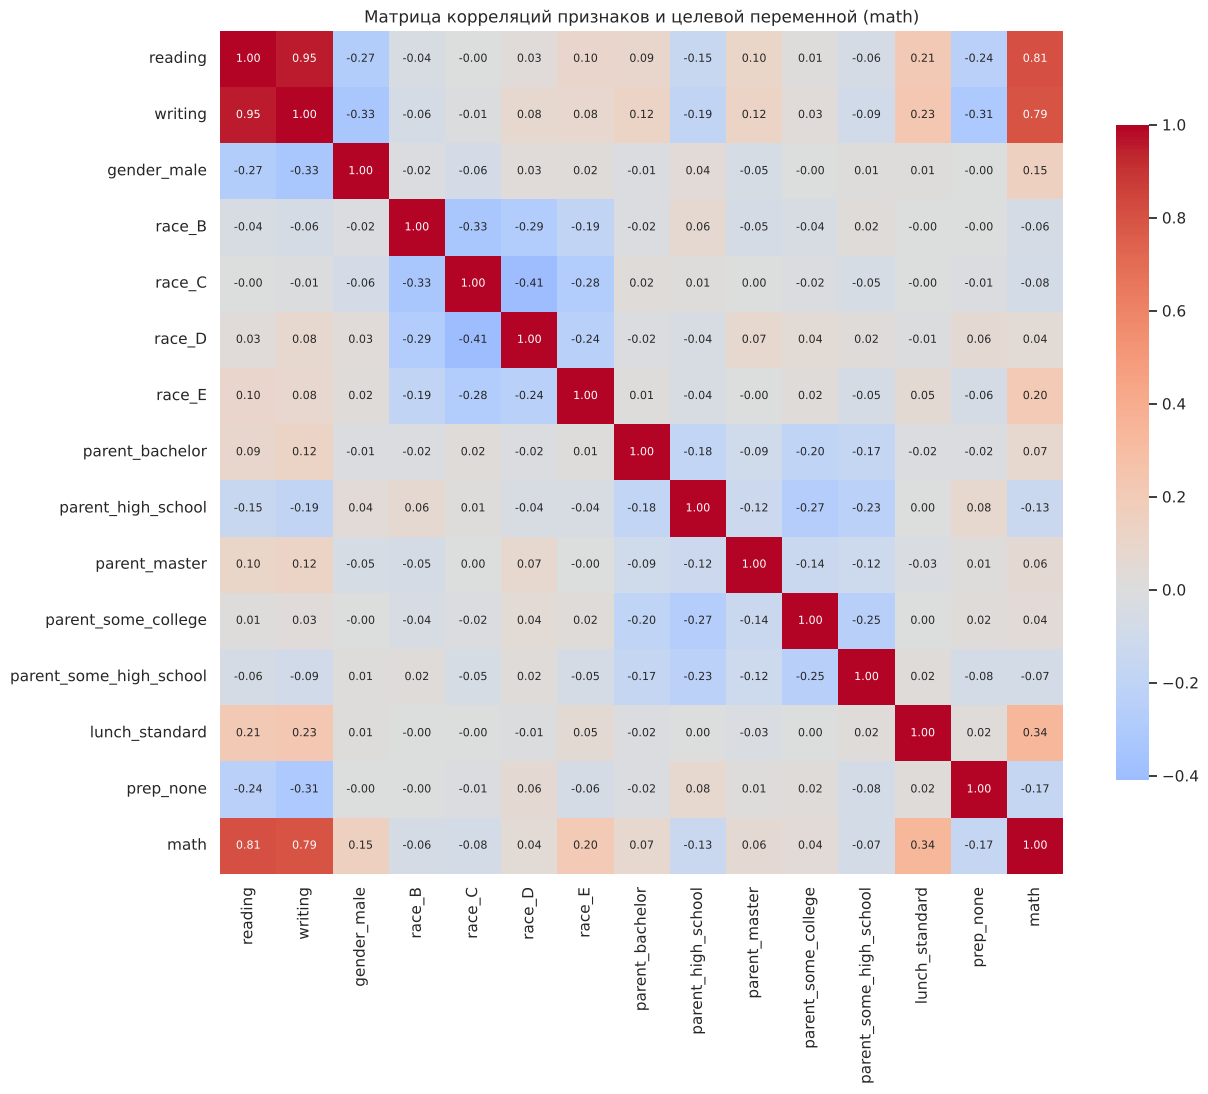

*Рисунок 7 — матрица корреляций признаков и целевой переменной*

**Связь с целевой переменной** (последняя строка матрицы):

- **сильнее всего** — `reading` (0.807) и `writing` (0.789);
- **умеренно** — `lunch_standard` (0.340), `race_E` (0.204), `prep_none` (−0.172),
  `gender_male` (0.150);
- **слабо** — индикаторы образования родителей (не более 0.13 по модулю).

**Между признаками** единственная пара с |r| > 0.5 — `reading` ↔ `writing` (0.953).
Индикаторы одного категориального признака слабо отрицательно коррелируют друг с другом
(например, `race_C` ↔ `race_D` ≈ −0.4): ученик может принадлежать только к одной группе.

**Коэффициент инфляции дисперсии** $VIF_j = \dfrac{1}{1 - R_j^2}$, где $R_j^2$ — коэффициент
детерминации регрессии признака $j$ на остальные признаки. VIF показывает, во сколько раз
дисперсия оценки коэффициента увеличена из-за корреляции с другими признаками.

Интерпретация: VIF = 1 — мультиколлинеарности нет; 1–5 — слабая; 5–10 — умеренная;
более 10 — сильная.

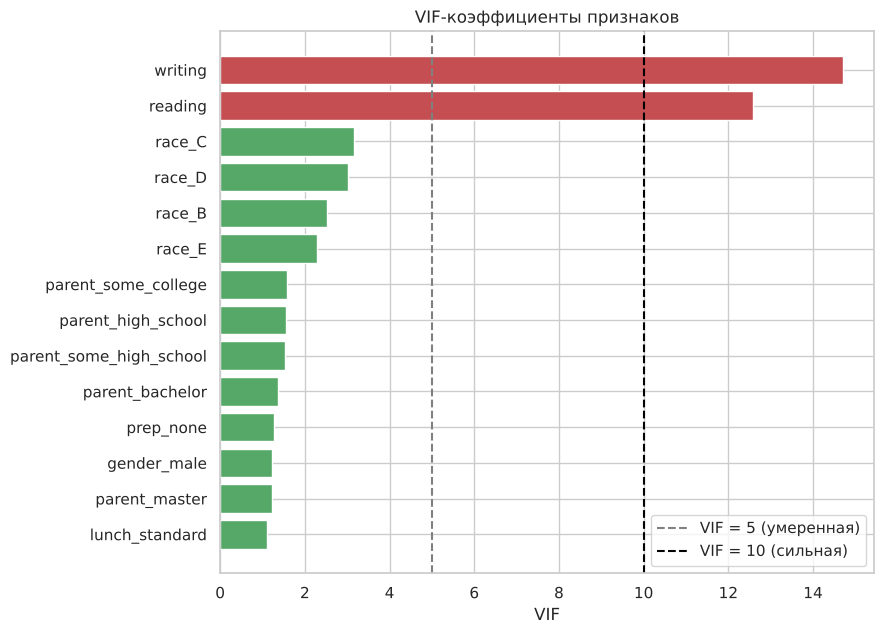

*Рисунок 8 — VIF-коэффициенты признаков*

| Признак | VIF |
|---|---|
| writing | **14.70** |
| reading | **12.58** |
| race_C, race_D, race_B, race_E | 2.28–3.17 |
| parent_* (5 индикаторов) | 1.22–1.57 |
| prep_none | 1.26 |
| gender_male | 1.23 |
| lunch_standard | 1.11 |

- **Сильная мультиколлинеарность (VIF > 10) — у пары `writing` (14.7) и `reading` (12.6).**
  Балл за письмо на 93% ($R^2 = 1 - 1/14.7$) объясняется остальными признаками, в первую
  очередь баллом за чтение. Дисперсия оценки его коэффициента завышена почти в 15 раз.
- **Индикаторы этнических групп** (VIF 2.3–3.2) имеют слабую связь — это следствие их
  взаимоисключающей структуры. Такой уровень допустим.
- **Остальные признаки** практически независимы: VIF не выше 1.6.

Проверка: если исключить `writing`, VIF `reading` падает до уровня остальных признаков
(менее 2.5).

**Вывод:** мультиколлинеарность в данных есть, но она **локальная и естественная**. Чтение
и письмо — два экзамена по родному языку, измеряющие одну и ту же способность, поэтому
коэффициенты при этих двух признаках будут неустойчивыми. Остальные признаки мультиколлинеарностью
не затронуты.

### 4.2 Регрессионные модели на исходных признаках

Были выбраны 3 регрессионные модели:

- **Линейная регрессия (МНК):** минимизирует сумму квадратов остатков
  $\sum (y_i - \hat y_i)^2$ без штрафов. При мультиколлинеарности оценки коэффициентов
  несмещённые, но неустойчивые.
- **Лассо-регрессия (L1-регуляризация):** добавляет штраф $\alpha \sum |\beta_j|$. Зануляет
  коэффициенты слабых признаков, то есть выполняет отбор признаков.
- **Гребневая регрессия (Ridge, L2-регуляризация):** добавляет штраф $\alpha \sum \beta_j^2$.
  Не зануляет коэффициенты, а сжимает их и распределяет вес между коррелированными признаками.
  Это классическое средство борьбы с мультиколлинеарностью.

**Параметры.** Коэффициент регуляризации α не задавался вручную, а подбирался по сетке из
30 значений с помощью `GridSearchCV` и 5-кратной кросс-валидации (критерий — RMSE):

- Lasso: α от $10^{-3}$ до $10^{1}$; выбрано **α ≈ 0.117**;
- Ridge: α от $10^{-3}$ до $10^{3}$; выбрано **α ≈ 1.27**.

Каждая модель оформлена как конвейер «стандартизация → модель» и дополнительно оценена
5-кратной кросс-валидацией на обучающей выборке.

**Используемые метрики качества:**

- **RMSE** $= \sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ — средняя ошибка прогноза в баллах;
- **R²** $= 1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ — доля объяснённой дисперсии;
- **MAPE** $= \frac{100\%}{n}\sum \left|\frac{y_i-\hat y_i}{y_i}\right|$ — средняя ошибка в процентах.

**Результаты:**

| Модель | α | CV RMSE | CV R² | Test RMSE | Test R² | Test MAPE, % |
|---|---|---|---|---|---|---|
| Linear | — | 5.50 ± 0.21 | 0.853 | **5.087** | **0.887** | **6.71** |
| Lasso | 0.117 | 5.47 ± 0.19 | 0.854 | 5.134 | 0.885 | 6.79 |
| Ridge | 1.27 | 5.50 ± 0.21 | 0.853 | 5.091 | 0.887 | 6.72 |

- **Качество высокое.** Модели объясняют **около 89% дисперсии** балла по математике.
  Типичная ошибка прогноза — **около 5 баллов** из 100, средняя относительная ошибка — 6.7%.
- **Метрики на тесте немного лучше, чем на кросс-валидации.** Это колебания конкретной тестовой
  выборки из 199 учеников. Переобучения нет: тогда метрики на тесте были бы хуже.
- **Три модели практически равны.** Различия в RMSE — сотые доли балла, меньше разброса
  по фолдам (±0.2). Регуляризация не изменила качество: при 793 наблюдениях и 14 признаках
  МНК не переобучается, а мультиколлинеарность затрагивает лишь два признака.

Подбор параметра регуляризации:

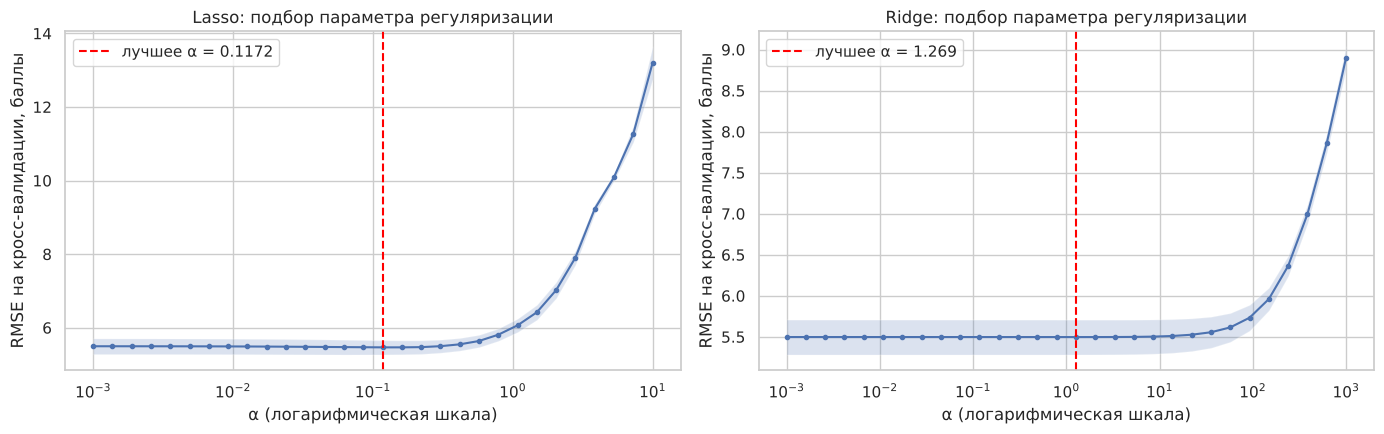

*Рисунок 9 — подбор параметра регуляризации α на кросс-валидации*

- **Lasso.** RMSE на кросс-валидации почти постоянна при малых α, неглубокий минимум —
  при α ≈ 0.12. При α > 1 штраф начинает обнулять значимые признаки, и ошибка быстро растёт.
- **Ridge.** Кривая плоская вплоть до α ≈ 10–30, затем ошибка растёт.

Плоские участки показывают, что регуляризация почти не влияет на точность прогноза.

Коэффициенты моделей (на стандартизованных признаках: изменение прогноза в баллах при росте
признака на одно стандартное отклонение):

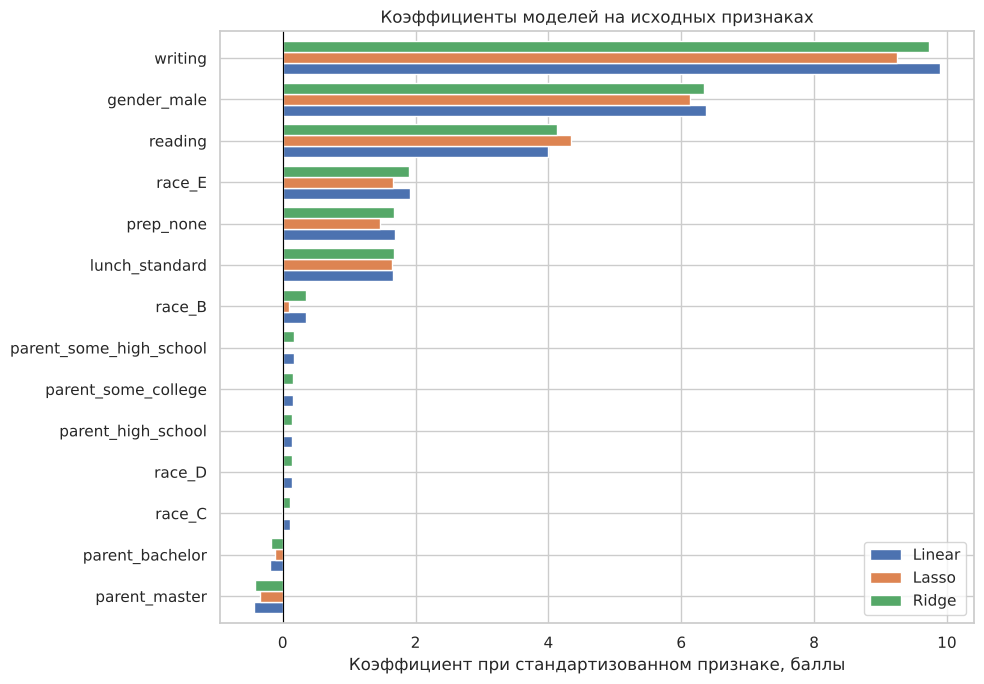

*Рисунок 10 — коэффициенты линейной, лассо- и гребневой регрессии*

| Признак | Linear | Lasso | Ridge | Linear, исходные единицы |
|---|---|---|---|---|
| writing | 9.89 | 9.24 | 9.73 | +0.67 за 1 балл |
| gender_male | 6.37 | 6.13 | 6.34 | **+12.7** балла |
| reading | 3.99 | 4.35 | 4.12 | +0.28 за 1 балл |
| race_E | 1.91 | 1.67 | 1.90 | +5.4 балла |
| prep_none | 1.69 | 1.46 | 1.67 | **+3.5** балла |
| lunch_standard | 1.66 | 1.65 | 1.67 | +3.5 балла |

**Влияние мультиколлинеарности.** Коэффициенты при `reading` и `writing` различаются в 2.5 раза,
хотя признаки почти взаимозаменяемы. Модели по-разному делят их общий вклад:

- Lasso перенесло часть веса с `writing` на `reading` (9.24 и 4.35);
- Ridge сгладил различие (9.73 и 4.12).

Суммарный вклад двух признаков стабилен (~13.9 во всех моделях), а распределение между ними
неустойчиво.

**Неочевидные знаки — эффект совместного учёта признаков:**

- **`gender_male` = +12.7 балла**, хотя в среднем юноши лучше девушек всего на 5 баллов.
  Коэффициент показывает разницу **при одинаковых баллах за чтение и письмо**. Юноши хуже
  по языку, поэтому при равных языковых баллах их преимущество в математике больше.
- **`prep_none` = +3.5 балла**: при равных баллах за чтение и письмо не проходившие курс
  ученики получают по математике **больше**. Курс сильнее повышает языковые баллы, чем
  математический. При одинаковом письме ученик без курса изначально сильнее, и это проявляется
  в математике.

Lasso обнулило 4 признака: `race_D`, `parent_high_school`, `parent_some_college`,
`parent_some_high_school`. Влияние образования родителей почти полностью опосредовано
баллами за чтение и письмо.

Модель «предсказано — реально»:

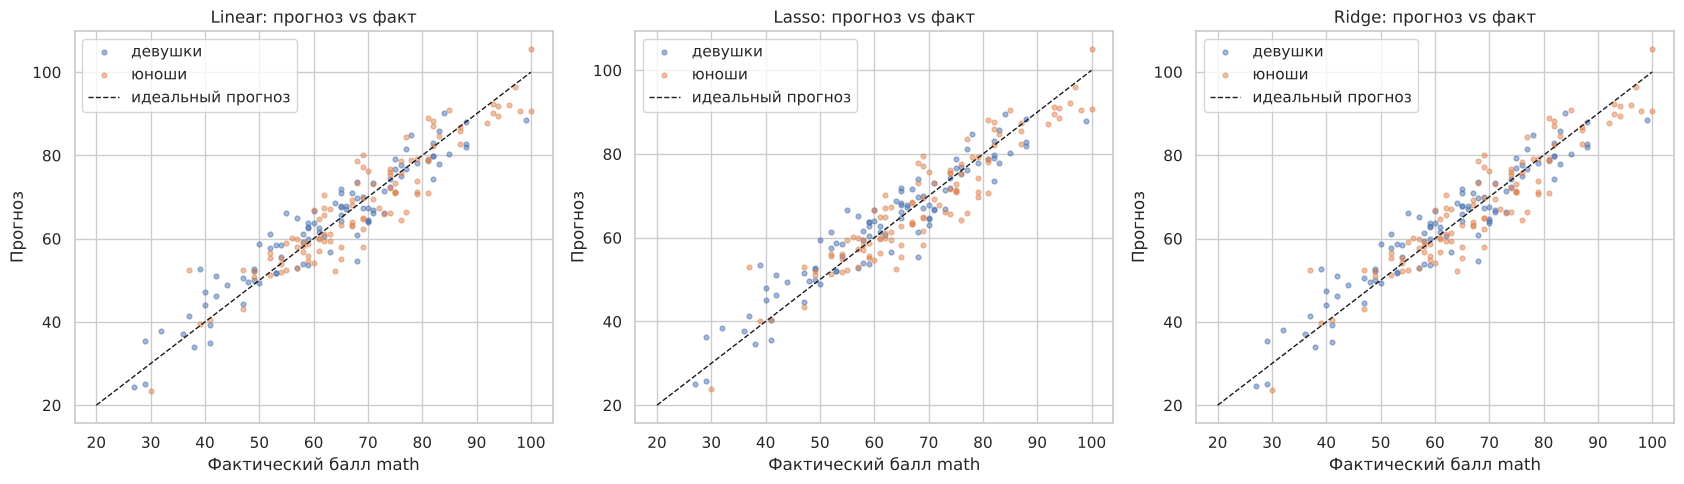

*Рисунок 11 — прогноз и фактические значения на тестовой выборке*

- Точки плотно лежат вдоль диагонали идеального прогноза по всему диапазону баллов — от 30
  до 100. Систематических отклонений нет.
- Ошибки юношей и девушек выглядят одинаково: учёт пола в модели устранил смещение,
  заметное на исходных диаграммах рассеяния.
- Прогнозы трёх моделей практически совпадают.

### 4.3 Анализ остатков

Остаток — разность фактического и предсказанного значения $e_i = y_i - \hat y_i$. Если разброс
остатков не зависит от прогноза, остатки **гомоскедастичны**; если зависит —
**гетероскедастичны**. Для проверки построены график «остатки — прогноз» с горизонтальной
линией на уровне 0 и гистограммы остатков. Проведены два теста:

- **тест Бройша–Пагана:** $H_0$ — дисперсия остатков постоянна;
- **тест Шапиро–Уилка:** $H_0$ — остатки распределены нормально.

Гипотезы отвергаются при p-value < 0.05.

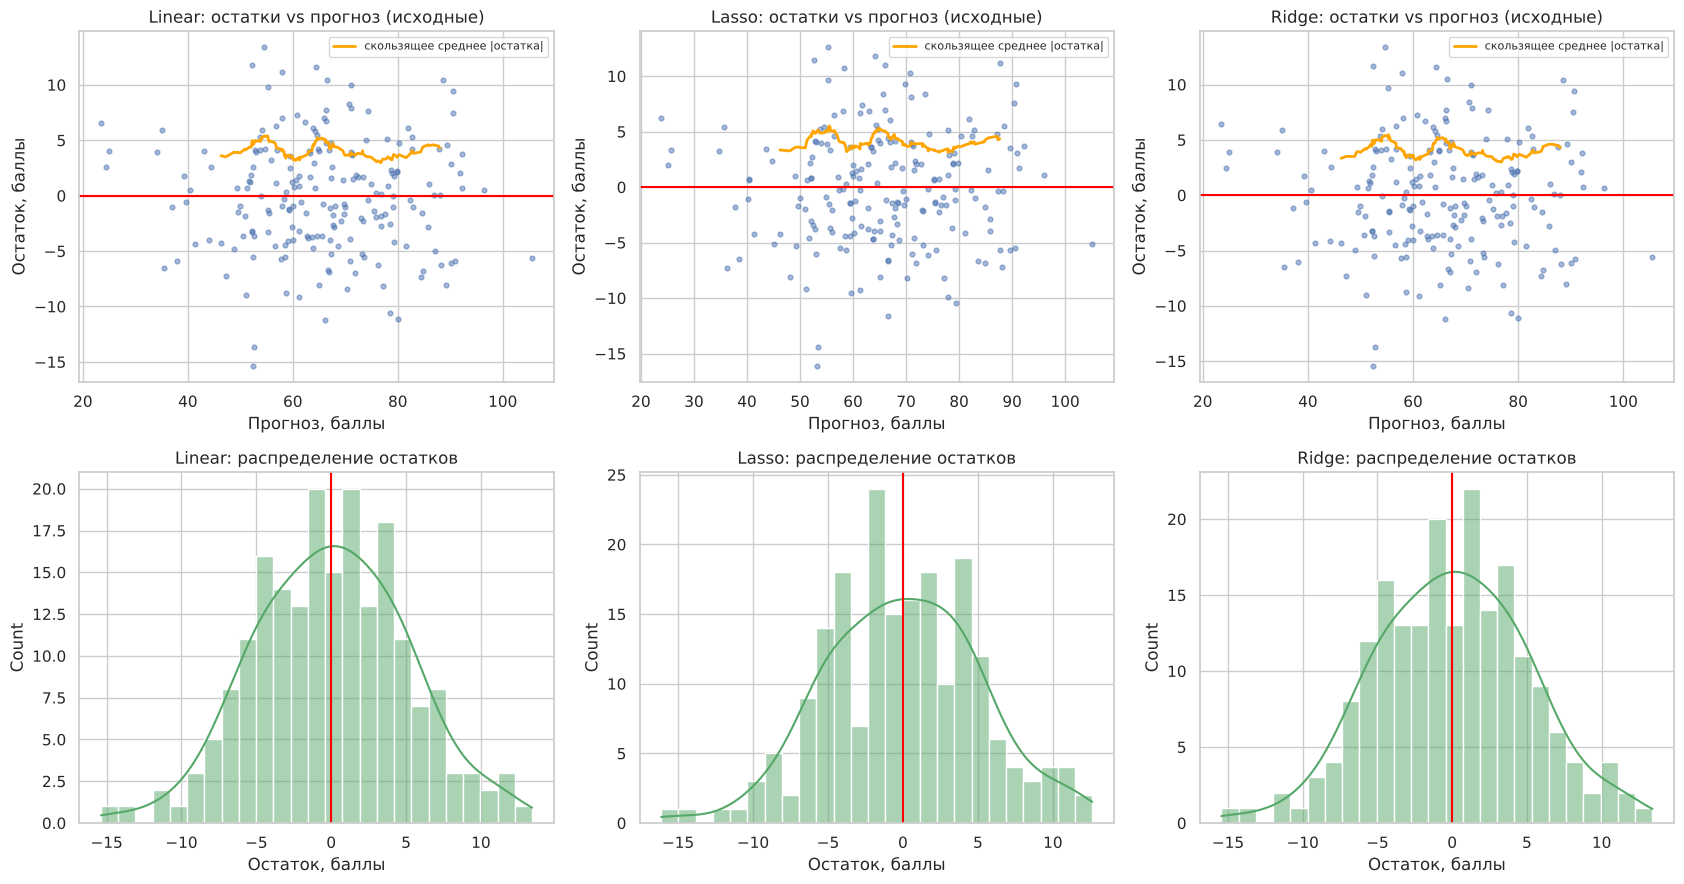

*Рисунок 12 — остатки моделей на исходных признаках*

| Модель | Среднее остатков | Std | Асимметрия | BP p-value | Shapiro p-value |
|---|---|---|---|---|---|
| Linear | −0.005 | 5.09 | −0.03 | 0.797 | 0.972 |
| Lasso | −0.005 | 5.13 | −0.06 | 0.710 | 0.759 |
| Ridge | −0.007 | 5.09 | −0.04 | 0.787 | 0.968 |

- **График остатков.** Точки образуют однородное облако, симметричное относительно нулевой линии,
  без воронок и изгибов. Почти все остатки лежат в пределах ±12 баллов. Скользящее среднее
  модуля остатка (оранжевая линия) держится на уровне 3.5–5 баллов по всему диапазону прогнозов.
- **Гистограммы** колоколообразные, с центром в нуле. Среднее остатков практически равно нулю,
  асимметрия ≈ 0.
- **Тест Бройша–Пагана** (p ≈ 0.71–0.80) не отвергает гомоскедастичность.
- **Тест Шапиро–Уилка** (p ≈ 0.76–0.97) не отвергает нормальность.

**Вывод:** остатки **гомоскедастичны и нормальны**. Все предпосылки классической линейной
регрессии выполнены. Поэтому оценки МНК эффективны, а стандартные ошибки и доверительные
интервалы корректны.

### 4.4 Устранение мультиколлинеарности с помощью PCA

Метод главных компонент заменяет коррелированные признаки их линейными комбинациями —
главными компонентами (ГК). Компоненты попарно некоррелированы и упорядочены по убыванию
объяснённой дисперсии. Перед PCA данные стандартизованы, PCA обучен только на обучающей
выборке.

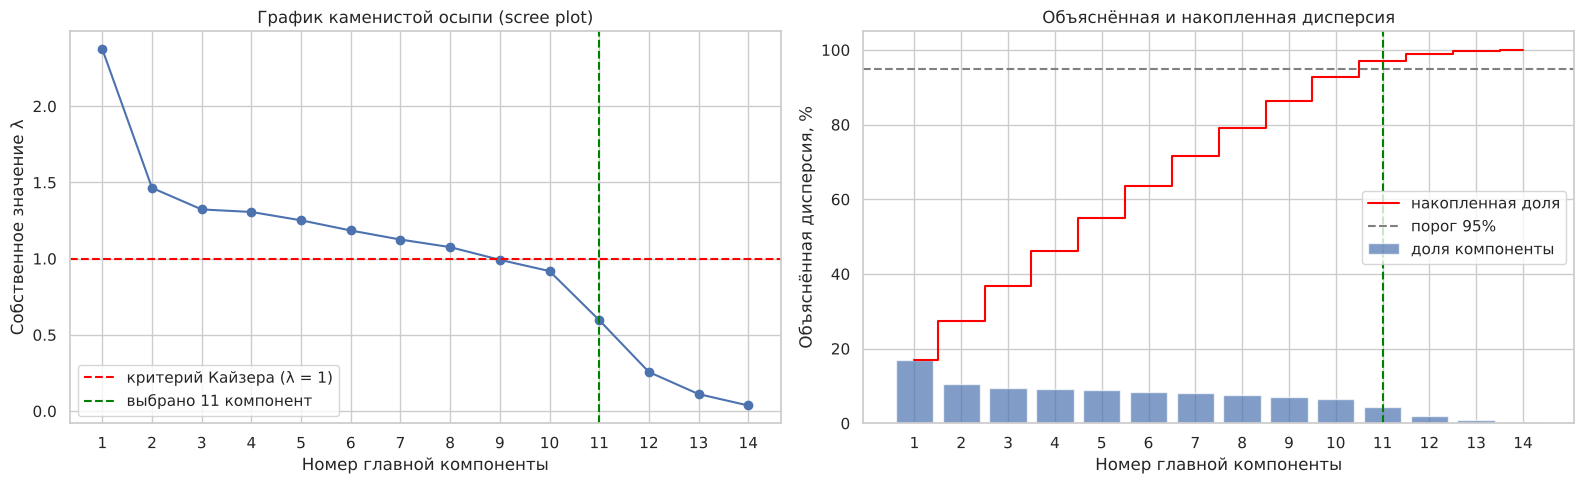

*Рисунок 13 — график каменистой осыпи и накопленная объяснённая дисперсия*

| Компонента | λ | Доля, % | Накопл., % |
|---|---|---|---|
| PC1 | 2.375 | 16.9 | 16.9 |
| PC2–PC8 | 1.46 … 1.08 | 10.4 … 7.7 | 27.4 … 79.2 |
| PC9 | 0.992 | 7.1 | 86.3 |
| PC10 | 0.918 | 6.6 | 92.9 |
| PC11 | 0.597 | 4.3 | **97.1** |
| PC12 | 0.256 | 1.8 | 98.9 |
| PC13 | 0.112 | 0.8 | 99.7 |
| PC14 | 0.037 | 0.3 | 100 |

**График каменистой осыпи (слева)** показывает собственные значения компонент:

- **Склон.** PC1 выделяется (λ = 2.38).
- **Плато.** Компоненты PC2–PC10 образуют пологий участок (λ от 1.46 до 0.92). Это примерно
  равнозначные комбинации индикаторов, которые PCA не может «сжать».
- **Обрыв.** После PC11 (λ = 0.60) следует резкий спад до 0.26, 0.11 и 0.04 — это «осыпь».

**Выбор числа компонент:**

- критерий Кайзера (λ > 1) даёт 8 компонент (79.2%);
- порог 90% даёт 10 компонент (92.9%);
- порог 95% даёт **11 компонент (97.1%)**.

Выбрано **11 компонент**: граница проходит ровно перед «осыпью». Отбрасываются три компоненты
с почти нулевыми собственными значениями, то есть вырожденные направления в пространстве
признаков. Размерность снижается с 14 до 11.

Нагрузки главных компонент (вклад исходных признаков):

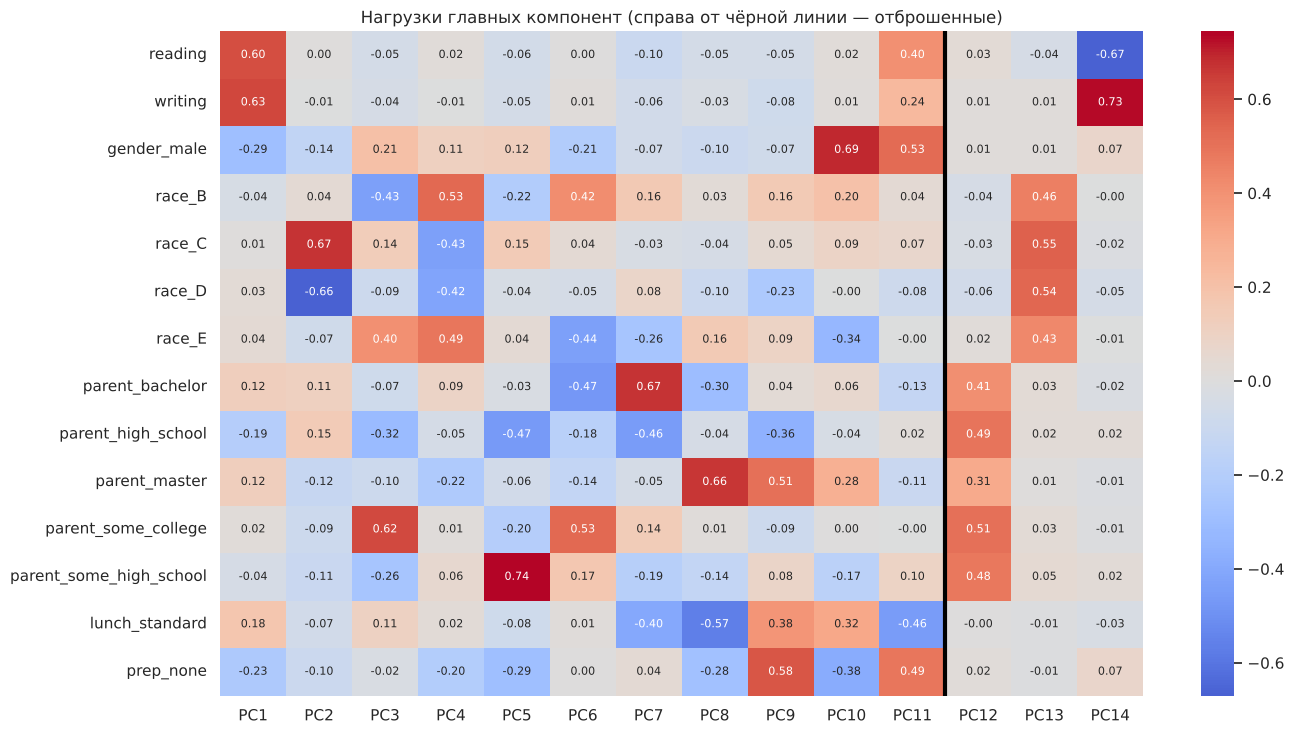

*Рисунок 14 — нагрузки главных компонент*

**Оставленные компоненты:**

- **PC1 — «успеваемость по языку».** `writing` (+0.63) и `reading` (+0.60) с равными весами.
  В неё же с меньшими весами входят `gender_male` (−0.29) и `prep_none` (−0.23): у девушек
  и прошедших курс языковые баллы выше. **Мультиколлинеарная пара свёрнута в один фактор.**
- **PC2–PC9** — комбинации индикаторов этнических групп и образования родителей. Например,
  PC2 — «группа C против группы D».
- **PC10 и PC11** — комбинации пола, подготовительного курса, питания и чтения.

**Отброшенные компоненты** — это именно вырожденные направления:

- **PC12** — сумма индикаторов образования родителей (все нагрузки +0.41…+0.51);
- **PC13** — сумма индикаторов этнических групп (+0.43…+0.55). Эти суммы почти постоянны,
  поскольку ученик относится ровно к одной категории;
- **PC14 = `writing` − `reading`** (+0.73 / −0.67) — разность почти совпадающих баллов.
  Именно это направление и порождало VIF ≈ 13–15.

Проверка устранения мультиколлинеарности:

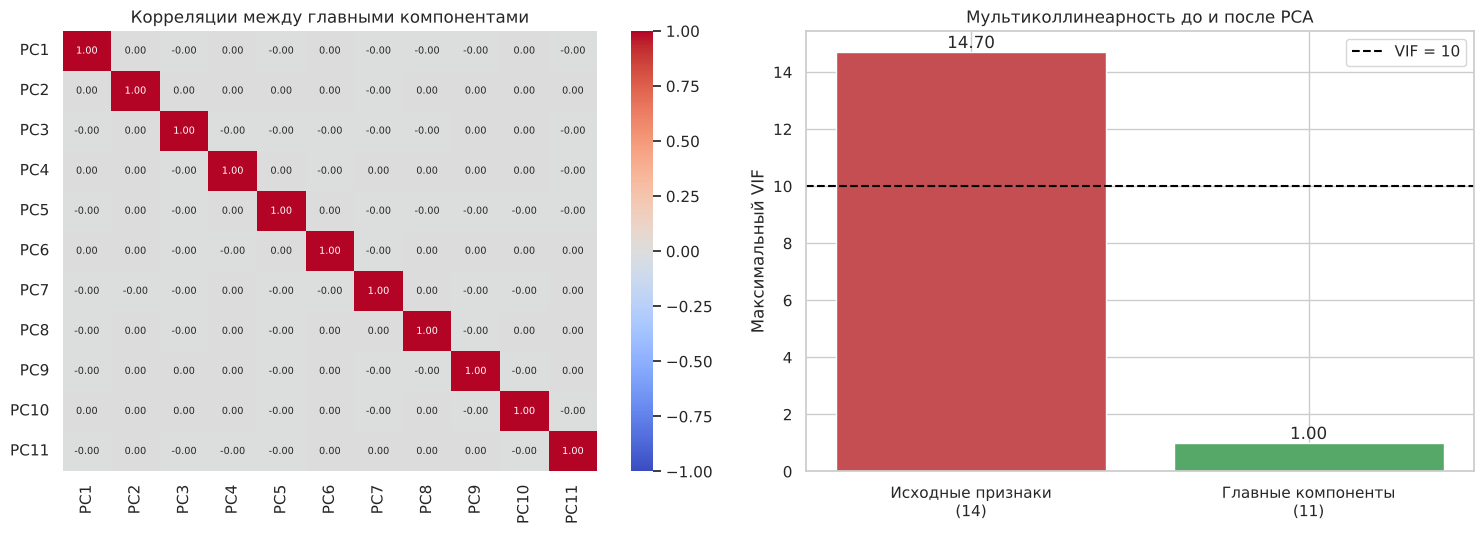

*Рисунок 15 — корреляции главных компонент и VIF до и после PCA*

Все внедиагональные корреляции между главными компонентами равны 0.00, у всех 11 компонент
**VIF = 1.0**. Максимальный VIF снизился **с 14.7 до 1.0**: мультиколлинеарность полностью
устранена.

### 4.5 Регрессия на главных компонентах и сравнение моделей

Модели линейной, лассо- и гребневой регрессии построены заново с теми же сетками α,
кросс-валидацией и разбиением. В качестве признаков использованы 11 главных компонент:
конвейер «стандартизация → PCA(11) → модель».

| Модель | α | CV RMSE | CV R² | Test RMSE | Test R² | Test MAPE, % |
|---|---|---|---|---|---|---|
| Linear (PCA) | — | 5.59 ± 0.22 | 0.848 | 5.268 | 0.879 | 7.01 |
| Lasso (PCA) | 0.045 | 5.58 ± 0.21 | 0.848 | 5.269 | 0.879 | 7.01 |
| Ridge (PCA) | 3.29 | 5.59 ± 0.22 | 0.848 | 5.273 | 0.879 | 7.01 |

На некоррелированных компонентах регуляризации нечего стабилизировать, поэтому все три модели
дают одинаковый результат.

Остатки моделей на главных компонентах:

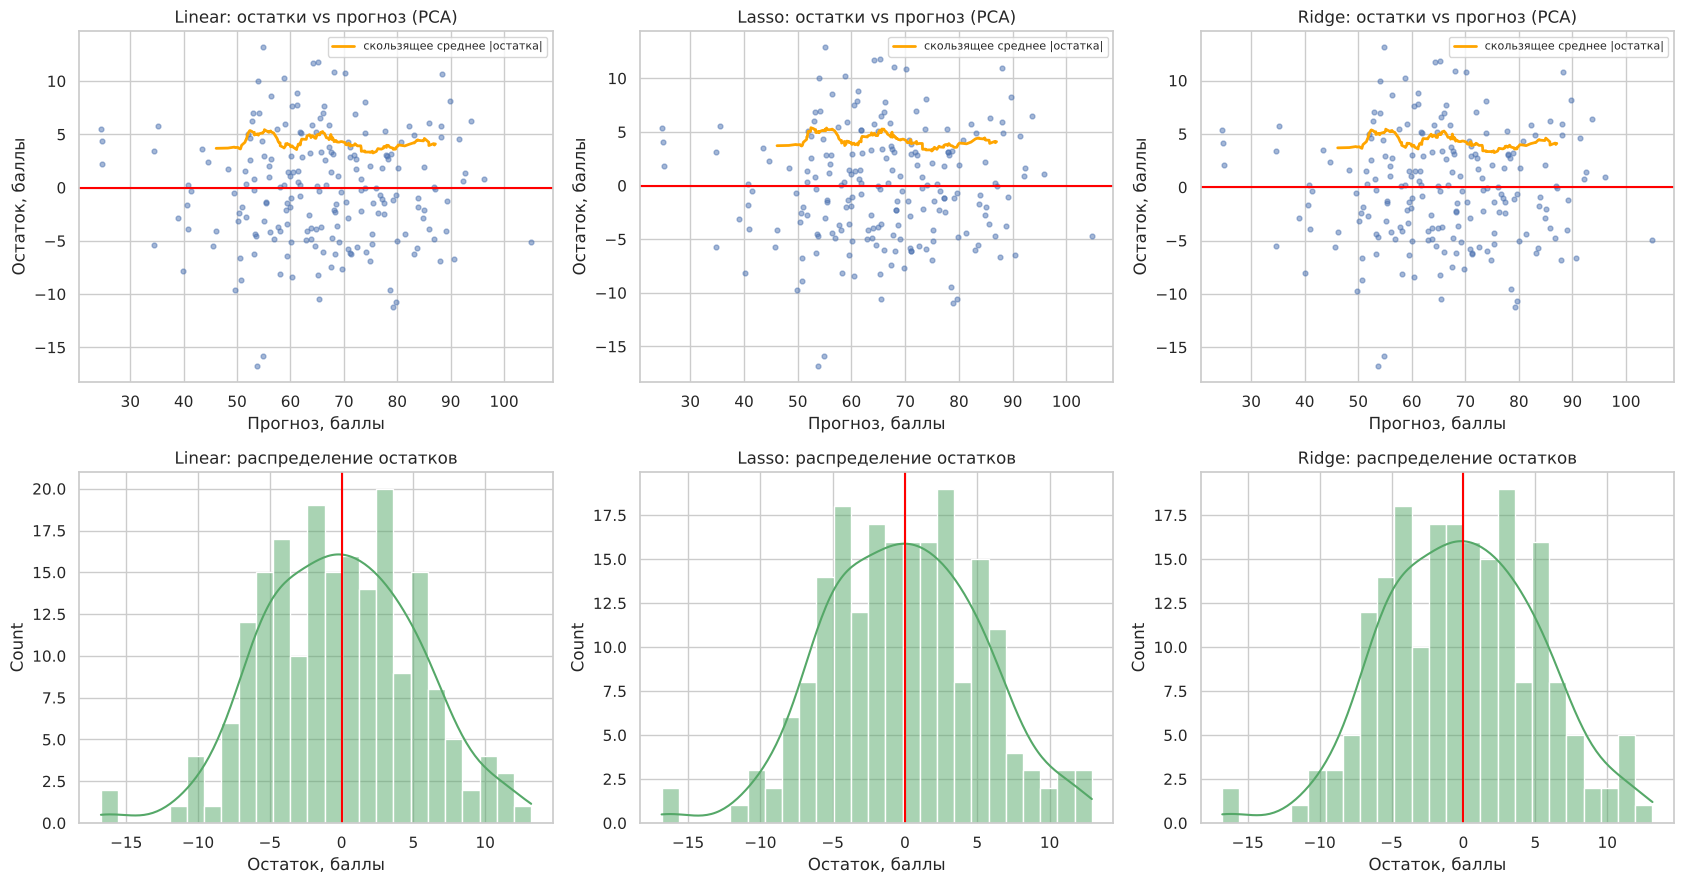

*Рисунок 16 — остатки моделей на главных компонентах*

Структура остатков та же, что на исходных признаках: однородное облако вокруг нуля,
колоколообразные гистограммы.

- Тест Бройша–Пагана (p ≈ 0.52–0.54) не отвергает гомоскедастичность.
- Тест Шапиро–Уилка (p ≈ 0.56–0.65) не отвергает нормальность.

Переход к главным компонентам не нарушил предпосылок регрессии.

Основные метрики до и после устранения мультиколлинеарности:

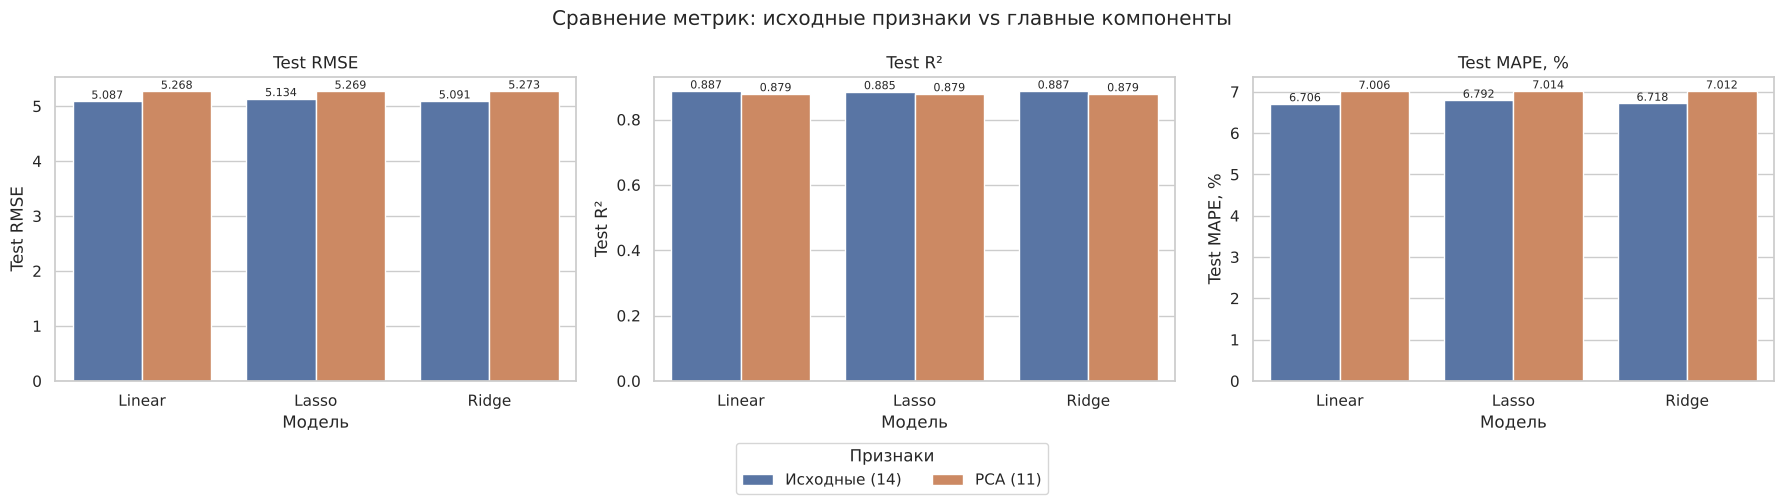

*Рисунок 17 — сравнение метрик моделей на исходных признаках и на главных компонентах*

| Модель | Test RMSE (исходные → PCA) | Test R² (исходные → PCA) | Test MAPE, % (исходные → PCA) |
|---|---|---|---|
| Linear | 5.087 → 5.268 (+0.18) | 0.887 → 0.879 | 6.71 → 7.01 |
| Lasso | 5.134 → 5.269 (+0.14) | 0.885 → 0.879 | 6.79 → 7.01 |
| Ridge | 5.091 → 5.273 (+0.18) | 0.887 → 0.879 | 6.72 → 7.01 |

- **RMSE (чем ниже, тем лучше):** модели на PCA-компонентах хуже на 0.14–0.18 балла (около 3%).
- **R² (чем ближе к 1, тем лучше):** снижение на 0.006–0.008.
- **MAPE (чем ниже, тем лучше):** рост на 0.2–0.3 процентного пункта.

На кросс-валидации RMSE выросла с 5.50 до 5.59, то есть на 0.09. Это **меньше** стандартного
отклонения по фолдам (±0.21). Ухудшение находится **в пределах статистического шума**:
модели на главных компонентах дают сопоставимое качество при меньшем числе некоррелированных
признаков.

Небольшая потеря связана с отброшенной компонентой PC14 (`writing` − `reading`). Баллы за
чтение и письмо почти совпадают, но не полностью: их разность несёт немного информации
о математике. Это видно и по неравным коэффициентам при них в исходной модели.

Зависимость качества модели от числа главных компонент:

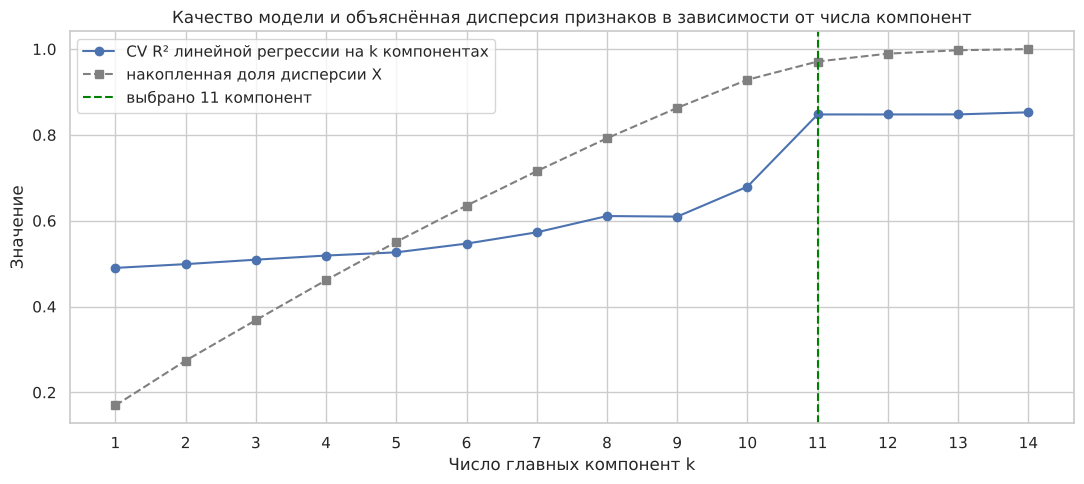

*Рисунок 18 — качество регрессии и объяснённая дисперсия в зависимости от числа компонент*

| k | 1 | 4 | 8 | 10 | **11** | 13 | 14 |
|---|---|---|---|---|---|---|---|
| CV R² | 0.490 | 0.519 | 0.611 | 0.679 | **0.848** | 0.848 | 0.853 |
| накопл. дисперсия, % | 16.9 | 46.1 | 79.2 | 92.9 | **97.1** | 99.7 | 100 |

- **Одна компонента PC1** («успеваемость по языку») сразу даёт R² = 0.49.
- **С PC2 по PC10** R² растёт медленно: эти компоненты описывают в основном этнические группы
  и образование родителей, слабо связанные с результатом.
- **При добавлении PC11 R² скачком растёт с 0.679 до 0.848.** Эта компонента содержит
  информацию о поле ученика в сочетании с языковыми баллами. Как показал анализ, именно
  такое сочетание сильно влияет на результат по математике.
- **После PC11 качество практически не меняется.**

Отсюда важный вывод о выборе числа компонент. При пороге 90% (10 компонент) модель потеряла бы
ключевую информацию, и R² упал бы до 0.68. PCA ранжирует компоненты по дисперсии признаков,
а не по их связи с целевой переменной. Поэтому число компонент нужно проверять
по качеству модели. Выбранные 11 компонент — минимальное число, при котором качество
сохраняется.

Модель «предсказано — реально» на исходных признаках и на главных компонентах:

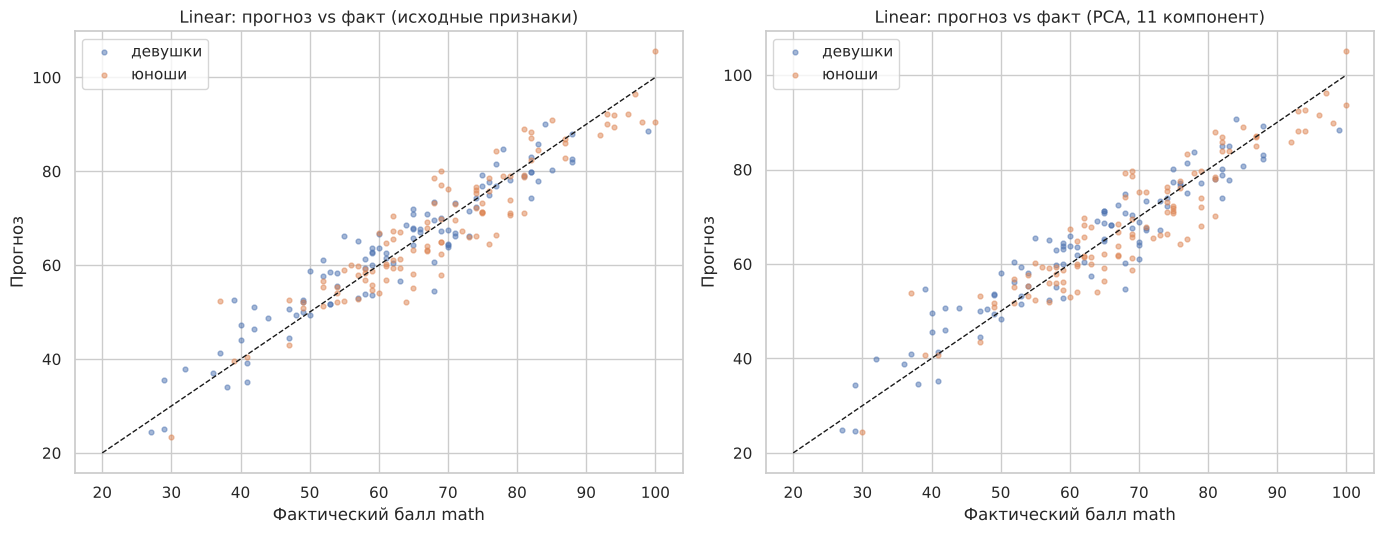

*Рисунок 19 — прогноз и факт: исходные признаки и главные компоненты*

Графики практически идентичны: на обоих точки плотно лежат вдоль диагонали, прогнозы для
юношей и девушек не смещены. Модель на 11 главных компонентах воспроизводит прогнозы исходной
модели, используя некоррелированные признаки.

### 4.6 Анализ погрешности и пути повышения точности

Лучшая модель — линейная регрессия на исходных признаках — ошибается в среднем на 5.1 балла
(RMSE) и на 6.7% (MAPE). Разберём, где и почему возникает погрешность.

**Распределение ошибок (тестовая выборка, 199 учеников):**

- ошибка не превышает 5 баллов у **67.8%** учеников;
- ошибка больше 10 баллов — у **5.5%** (11 учеников);
- максимальная ошибка — 15.4 балла.

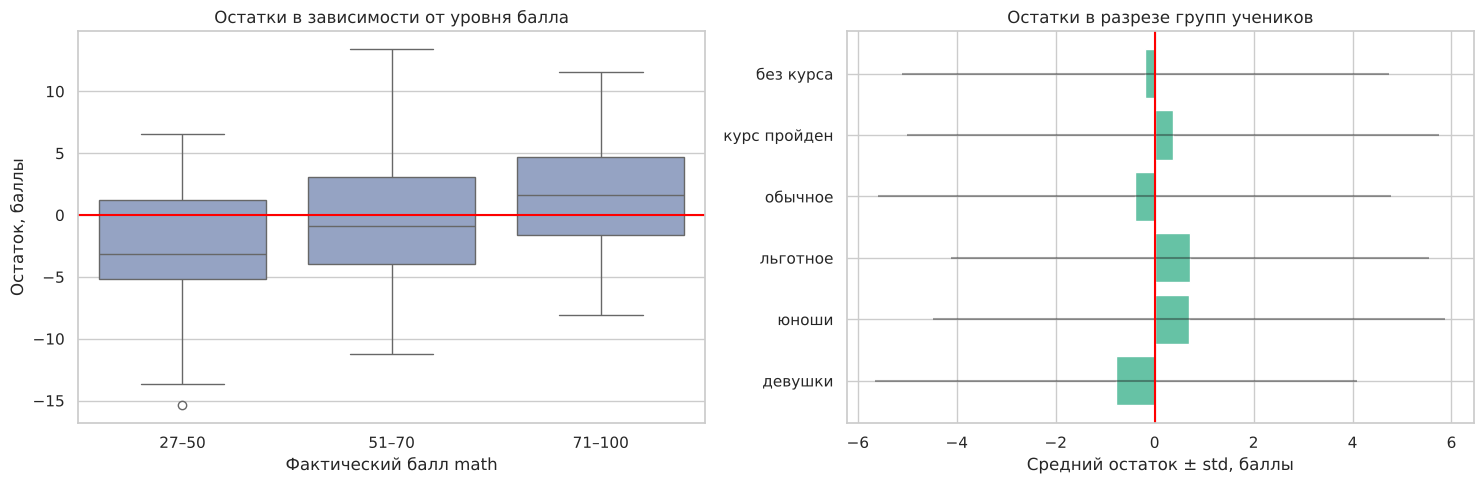

*Рисунок 20 — остатки по уровню балла и в разрезе групп учеников*

| Уровень балла | Учеников | RMSE | MAPE, % | Средний остаток |
|---|---|---|---|---|
| 27–50 | 31 | 5.72 | 11.66 | −2.46 |
| 51–70 | 95 | 5.04 | 6.55 | −0.44 |
| 71–100 | 73 | 4.86 | 4.80 | +1.61 |

**Причины погрешности:**

1. **«Стягивание» прогнозов к среднему.** У слабых учеников средний остаток отрицательный
   (−2.5): модель **завышает** им балл. У сильных — положительный (+1.6): модель **занижает**.
   Это типичное свойство регрессии при неполной информации: модель «осторожничает»
   и стягивает прогноз к среднему. На графике слева медианы ящиков смещаются снизу вверх.
2. **MAPE выше у слабых учеников** (11.7% против 4.8%), хотя RMSE во всех группах близка
   (4.9–5.7 балла). Та же абсолютная ошибка в 5 баллов составляет 13% от балла 40, но лишь 6%
   от балла 85. Это свойство самой метрики MAPE.
3. **Систематических ошибок по группам практически нет.** Средний остаток в группах по полу,
   питанию и подготовке — от −0.8 до +0.7 балла, что много меньше разброса (std ≈ 5).
   Модель корректно учитывает все имеющиеся признаки (график справа).
4. **Главная причина — неучтённые факторы.** Признаки описывают способность к языкам и
   социальный фон, но не математические способности напрямую. Нет данных о прошлых оценках,
   времени на подготовку, посещаемости, мотивации. Также есть случайность в день экзамена.
   Эта часть дисперсии (~11%) **не может быть объяснена никакой моделью** на имеющихся признаках.
5. **Дискретность и ограниченность шкалы.** Баллы целые и не превышают 100, а линейная модель
   этого не учитывает. Например, для одного ученика прогноз — 105.6 балла.

**Эксперименты по повышению точности.** Проверены подходы из трёх групп: изменение масштаба
признаков, регуляризация и более сложная модель. Все оценены по той же схеме — 5-кратная
кросс-валидация на обучающей выборке и проверка на тестовой.

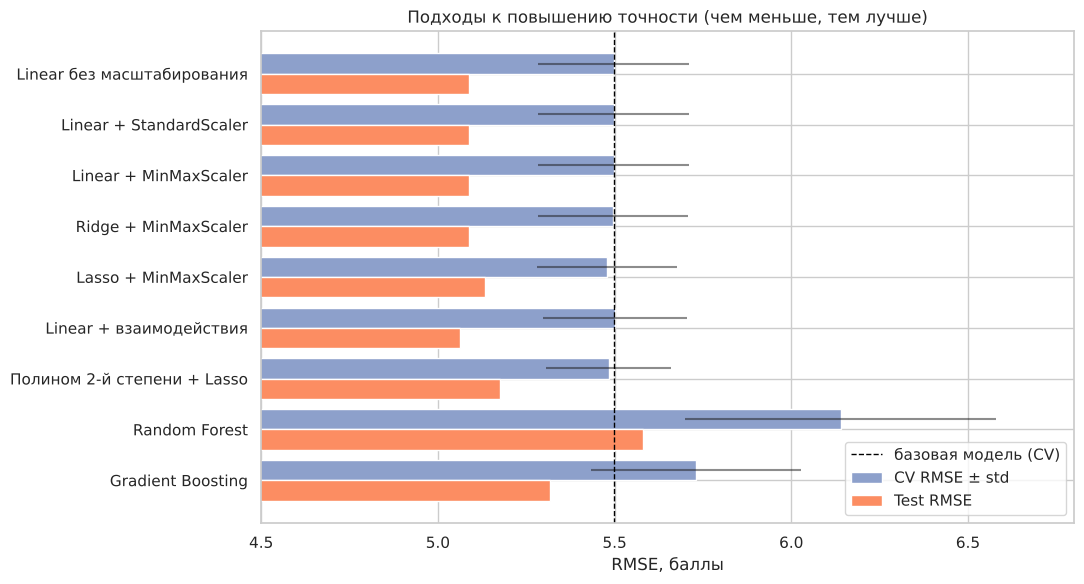

*Рисунок 21 — сравнение подходов к повышению точности*

| Подход | CV RMSE | CV R² | Test RMSE | Test R² | Test MAPE, % |
|---|---|---|---|---|---|
| Linear без масштабирования | 5.497 ± 0.213 | 0.853 | 5.087 | 0.887 | 6.71 |
| Linear + StandardScaler | 5.497 ± 0.213 | 0.853 | 5.087 | 0.887 | 6.71 |
| Linear + MinMaxScaler | 5.497 ± 0.213 | 0.853 | 5.087 | 0.887 | 6.71 |
| Ridge + MinMaxScaler | 5.496 ± 0.213 | 0.853 | 5.088 | 0.887 | 6.71 |
| Lasso + MinMaxScaler | 5.479 ± 0.199 | 0.854 | 5.132 | 0.885 | 6.78 |
| Linear + взаимодействия (пол × баллы, курс × письмо) | 5.501 ± 0.204 | 0.853 | **5.063** | **0.888** | **6.67** |
| Полином 2-й степени + Lasso | 5.483 ± 0.176 | 0.853 | 5.177 | 0.883 | 6.84 |
| Random Forest | 6.139 ± 0.439 | 0.815 | 5.580 | 0.864 | 7.47 |
| Gradient Boosting | 5.731 ± 0.297 | 0.840 | 5.317 | 0.877 | 6.94 |

- **Изменение масштаба признаков** (стандартизация или Min-Max) **не влияет** на обычную линейную
  регрессию: метрики совпадают до 4-го знака. МНК инвариантен к линейному преобразованию
  признаков, меняются только сами коэффициенты. Для Lasso и Ridge масштабирование необходимо
  (иначе штраф действует неравномерно), но выбор между стандартизацией и Min-Max на качество
  почти не влияет.
- **Регуляризация** (Ridge, Lasso) не дала значимого выигрыша: изменения RMSE меньше 0.02
  балла при разбросе ±0.21. Модель не переобучена — 14 признаков на 793 наблюдения, — поэтому
  ограничивать её сложность не нужно.
- **Расширение признакового пространства.** Взаимодействия признаков и полиномиальные признаки
  2-й степени (119 признаков с отбором через Lasso) не улучшили кросс-валидацию. Небольшой
  выигрыш взаимодействий на тесте (5.063 против 5.087) находится в пределах шума. Значит,
  зависимость балла от признаков действительно **линейна**.
- **Более сложные модели.** Случайный лес и градиентный бустинг оказались **хуже** линейной
  регрессии (CV RMSE 6.14 и 5.73 против 5.50). Деревья аппроксимируют линейную зависимость
  «ступеньками», и при 793 наблюдениях это даёт большую ошибку.

**Вывод.** Линейная регрессия уже близка к пределу точности, достижимому на этих признаках.
Оставшаяся погрешность (~5 баллов) — информация, которой нет в данных, а не недостаток модели.

Повысить точность можно только за счёт **новых признаков**, непосредственно связанных
с математикой:

- оценки по предмету за год;
- результаты пробных экзаменов;
- время на подготовку.

Из технических улучшений имеет смысл ограничение прогноза диапазоном [0; 100].

## 5. Заключение

В работе построены и исследованы модели линейной, лассо- и гребневой регрессии, предсказывающие
балл ученика по математике по датасету Students Performance in Exams (1 000 учеников,
8 столбцов).

**По результатам анализа данных:**

- пропусков и дубликатов нет;
- баллы распределены близко к нормальному;
- удалены 8 выбросов с баллом по математике ниже 27, включая нулевой балл, при котором
  MAPE не определена;
- результат по математике сильнее всего связан с баллами за чтение (r = 0.82) и письмо (0.80),
  затем с типом питания (показатель достатка семьи), этнической группой, подготовительным курсом
  и полом.

**По таблице корреляций и VIF-коэффициентам:**

- обнаружена **естественная мультиколлинеарность** пары `reading` — `writing` (r = 0.955,
  VIF 12.6 и 14.7): оба экзамена измеряют владение языком;
- у индикаторов этнических групп VIF 2.3–3.2, у остальных признаков — не выше 1.6.
  Мультиколлинеарность локальна и затрагивает только два признака.

**По регрессионным моделям на исходных признаках:**

- все три модели показали практически одинаковое высокое качество: Test RMSE ≈ 5.1 балла,
  R² ≈ 0.887, MAPE ≈ 6.7%. Лучшая — линейная регрессия (RMSE = 5.087);
- мультиколлинеарность проявилась в неустойчивом разделении веса между `reading` и `writing`;
- совместный учёт признаков выявил неочевидные эффекты. При равных языковых баллах юноши
  получают по математике на 12.7 балла больше, а не проходившие подготовительный курс —
  на 3.5 балла больше;
- Lasso обнулило 4 признака, в основном индикаторы образования родителей: их влияние
  опосредовано языковыми баллами.

**По остаткам:** остатки гомоскедастичны (тест Бройша–Пагана, p ≈ 0.8) и нормальны
(тест Шапиро–Уилка, p ≈ 0.97). Предпосылки линейной регрессии выполнены.

**По PCA (каменистая осыпь):**

- выбрано 11 главных компонент из 14 (97.1% дисперсии), граница проходит перед «осыпью»;
- первая компонента («успеваемость по языку») объясняет 17% дисперсии;
- отброшенные компоненты соответствуют вырожденным направлениям: разности `writing` − `reading`
  и суммам индикаторов;
- мультиколлинеарность полностью устранена: VIF снизился с 14.7 до 1.0.

**По сравнению исходных данных и PCA:**

- модели на главных компонентах дают **сопоставимое качество**: RMSE 5.27 против 5.09,
  R² 0.879 против 0.887, MAPE 7.0% против 6.7%;
- ухудшение (~3% по RMSE) находится в пределах разброса кросс-валидации;
- число компонент нельзя выбирать только по доле дисперсии: при 10 компонентах R² падает
  до 0.68, так как теряется компонента с информацией о поле.

**По анализу погрешности:**

- у 68% учеников ошибка не превышает 5 баллов;
- модель слегка «стягивает» прогнозы к среднему: завышает балл слабым ученикам и занижает
  сильным;
- систематических ошибок по группам нет.

Проверены изменение масштаба признаков (стандартизация, Min-Max), регуляризация, взаимодействия
и полиномиальные признаки, случайный лес и градиентный бустинг. Ни один подход не улучшил
точность значимо: зависимость линейна, а оставшаяся погрешность вызвана неучтёнными факторами.
Повысить точность можно, только добавив признаки, напрямую связанные с математикой (оценки,
пробные экзамены, время подготовки).

**Общий вывод.** Естественная мультиколлинеарность пары «чтение — письмо» не мешает прогнозу,
но делает неустойчивыми отдельные коэффициенты. Метод главных компонент устранил её и сократил
число признаков с 14 до 11 практически без потери качества. Если цель — интерпретируемые
и устойчивые коэффициенты, предпочтительна модель на главных компонентах или гребневая
регрессия. Если цель — максимальная точность прогноза, достаточно обычной линейной регрессии
на исходных признаках.

## 6. Список источников

1. Students Performance in Exams [Электронный ресурс] // Kaggle. —
   URL: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
2. Кремер Н. Ш., Путко Б. А. Эконометрика : учебник для студентов вузов. — 3-е изд.,
   перераб. и доп. — Москва : ЮНИТИ-ДАНА, 2010. — 328 с.
3. Айвазян С. А., Мхитарян В. С. Прикладная статистика и основы эконометрики : учебник для
   вузов. — Москва : ЮНИТИ, 1998. — 1022 с.
4. James G., Witten D., Hastie T., Tibshirani R., Taylor J. An Introduction to Statistical
   Learning: with Applications in Python. — Springer, 2023. — URL: https://www.statlearning.com
5. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. — 2nd ed. —
   Springer, 2009. — 745 p.
6. Tibshirani R. Regression Shrinkage and Selection via the Lasso // Journal of the Royal
   Statistical Society, Series B. — 1996. — Vol. 58, No. 1. — P. 267–288.
7. Hoerl A. E., Kennard R. W. Ridge Regression: Biased Estimation for Nonorthogonal Problems //
   Technometrics. — 1970. — Vol. 12, No. 1. — P. 55–67.
8. Breusch T. S., Pagan A. R. A Simple Test for Heteroscedasticity and Random Coefficient
   Variation // Econometrica. — 1979. — Vol. 47, No. 5. — P. 1287–1294.
9. Документация scikit-learn: Linear Models, PCA, Cross-validation [Электронный ресурс]. —
   URL: https://scikit-learn.org/stable/user_guide.html
10. Документация statsmodels: variance_inflation_factor, het_breuschpagan [Электронный ресурс]. —
    URL: https://www.statsmodels.org/stable/

## 7. Исходный код программы

In [ ]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
TEST_SIZE = 0.2
FILE_NAME = "StudentsPerformance.csv"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=100, bbox_inches="tight")
    plt.show()
    plt.close()


def header(title):
    print("\n" + "=" * 70 + f"\n{title}\n" + "=" * 70)


# ======================================================================
header("1. ЗАГРУЗКА ДАННЫХ")
# ======================================================================
if not os.path.exists(FILE_NAME):
    raise FileNotFoundError(f"Файл '{FILE_NAME}' не найден в {os.getcwd()}")

df = pd.read_csv(FILE_NAME)
print(f"Загружено: {df.shape[0]} строк, {df.shape[1]} столбцов")
# короткие имена столбцов
df.columns = ["gender", "race", "parent_edu", "lunch", "prep", "math", "reading", "writing"]
print(df.head(10))

SCORES = ["math", "reading", "writing"]
CATS = ["gender", "race", "parent_edu", "lunch", "prep"]


# ======================================================================
header("2. ПЕРВИЧНЫЙ АНАЛИЗ ДАННЫХ")
# ======================================================================
print("\n--- Типы и пропуски ---")
print(pd.DataFrame({"тип": df.dtypes.astype(str), "пропусков": df.isnull().sum(),
                    "уникальных": df.nunique()}))
print(f"\nПолных дубликатов строк: {df.duplicated().sum()}")

print("\n--- Описательная статистика ---")
print(df.describe().round(2))
for col in SCORES:
    print(f"Асимметрия {col}: {stats.skew(df[col]):.3f}")

# Распределение баллов (целевая переменная — math)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, color in zip(axes, SCORES, ["#4C72B0", "#55A868", "#C44E52"]):
    ax.hist(df[col], bins=30, color=color)
    ax.axvline(df[col].mean(), color="black", ls="--", label=f"среднее = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="orange", ls="-.", label=f"медиана = {df[col].median():.0f}")
    ax.set_title(f"{col} score" + (" (целевая переменная)" if col == "math" else ""))
    ax.set_xlabel("Балл")
    ax.set_ylabel("Число учеников")
    ax.legend()
save("01_scores")

# Категориальные признаки
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, col in zip(axes, CATS):
    vc = df[col].value_counts()
    ax.bar(vc.index, vc.values, color="#8172B2")
    ax.bar_label(ax.containers[0])
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylabel("Число учеников")
save("02_categorical")

# Связь баллов между собой
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (xcol, ycol) in zip(axes, [("reading", "math"), ("writing", "math"), ("reading", "writing")]):
    sns.scatterplot(data=df, x=xcol, y=ycol, hue="gender", hue_order=["female", "male"],
                    alpha=0.5, s=20, ax=ax)
    ax.set_title(f"{ycol} vs {xcol} (r = {df[xcol].corr(df[ycol]):.3f})")
save("03_scatter")

# Балл по математике по группам
print("\n--- Средние баллы по группам ---")
for col in CATS:
    print(df.groupby(col)[SCORES].mean().round(1), "\n")
fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, col in zip(axes, CATS):
    order = df.groupby(col)["math"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="math", order=order, ax=ax)
    ax.tick_params(axis="x", rotation=35)
    ax.set_title(f"math — {col}")
save("04_groups")

# Корреляции исходных признаков (бинарные закодированы 0/1)
enc = df.assign(gender_male=(df["gender"] == "male").astype(int),
                lunch_standard=(df["lunch"] == "standard").astype(int),
                prep_none=(df["prep"] == "none").astype(int))
corr_raw = enc[["math", "reading", "writing", "gender_male", "lunch_standard", "prep_none"]].corr()
print("--- Корреляции исходных признаков ---")
print(corr_raw.round(3))
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_raw, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Корреляционная матрица исходных признаков")
save("05_corr_raw")


# ======================================================================
header("3. ПРЕДОБРАБОТКА ДАННЫХ")
# ======================================================================
print(f"Пропусков всего: {df.isnull().sum().sum()}, дубликатов: {df.duplicated().sum()}")

print("\n--- Выбросы по правилу 1.5·IQR ---")
for col in SCORES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(f"  {col:8s}: границы [{q1 - 1.5 * iqr:.2f}; {q3 + 1.5 * iqr:.2f}], выбросов {len(out)}: "
          f"{sorted(out[col].tolist())}")

q1, q3 = df["math"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("\nУдаляемые наблюдения (выбросы целевой переменной):")
print(df[(df["math"] < low) | (df["math"] > high)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df[SCORES], orient="h", ax=axes[0])
axes[0].set_title(f"До удаления выбросов (n = {len(df)})")
df = df[(df["math"] >= low) & (df["math"] <= high)].reset_index(drop=True)
sns.boxplot(data=df[SCORES], orient="h", ax=axes[1])
axes[1].set_title(f"После удаления выбросов math (n = {len(df)})")
for ax in axes:
    ax.set_xlabel("Балл")
save("06_outliers")
print(f"\nОсталось строк: {len(df)}")

# Кодирование категориальных переменных (One-Hot)
data = pd.get_dummies(df, columns=CATS, drop_first=True, dtype=int)
data = data.rename(columns={
    "race_group B": "race_B", "race_group C": "race_C", "race_group D": "race_D", "race_group E": "race_E",
    "parent_edu_bachelor's degree": "parent_bachelor", "parent_edu_high school": "parent_high_school",
    "parent_edu_master's degree": "parent_master", "parent_edu_some college": "parent_some_college",
    "parent_edu_some high school": "parent_some_high_school",
})
X = data.drop(columns="math")
y = data["math"]
print(f"\nМатрица признаков: {X.shape}, признаки: {list(X.columns)}")

# Разделение 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Средний балл math: train = {y_train.mean():.2f}, test = {y_test.mean():.2f}")

# Стандартизация (параметры только по train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ======================================================================
header("4. КОРРЕЛЯЦИОННЫЙ АНАЛИЗ И VIF")
# ======================================================================
corr = pd.concat([X, y], axis=1).corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, square=True, cbar_kws={"shrink": 0.75})
plt.title("Матрица корреляций признаков и целевой переменной (math)")
save("07_corr_full")

print("--- Корреляция признаков с math ---")
print(corr["math"].drop("math").sort_values(ascending=False).round(3))
pairs = (corr.drop(index="math", columns="math")
         .where(np.triu(np.ones((X.shape[1], X.shape[1]), dtype=bool), k=1)).stack())
print("\n--- Пары признаков с |r| > 0.5 ---")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3))


def calc_vif(frame):
    Xc = sm.add_constant(frame.astype(float))
    return pd.DataFrame({
        "Признак": frame.columns,
        "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(frame.shape[1])],
    }).sort_values("VIF", ascending=False).reset_index(drop=True)


vif_data = calc_vif(X)
print("\n--- VIF ---")
print(vif_data.round(2).to_string(index=False))
print("\nVIF без writing:")
print(calc_vif(X.drop(columns="writing")).head(3).round(2).to_string(index=False))

plt.figure(figsize=(9, 6.5))
colors = ["#C44E52" if v >= 10 else "#DD8452" if v >= 5 else "#55A868" for v in vif_data["VIF"]]
plt.barh(vif_data["Признак"], vif_data["VIF"], color=colors)
plt.axvline(5, ls="--", c="gray", label="VIF = 5 (умеренная)")
plt.axvline(10, ls="--", c="black", label="VIF = 10 (сильная)")
plt.gca().invert_yaxis()
plt.xlabel("VIF")
plt.title("VIF-коэффициенты признаков")
plt.legend()
save("08_vif")


# ======================================================================
header("5. РЕГРЕССИОННЫЕ МОДЕЛИ НА ИСХОДНЫХ ПРИЗНАКАХ")
# ======================================================================
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ALPHAS_LASSO = np.logspace(-3, 1, 30)
ALPHAS_RIDGE = np.logspace(-3, 3, 30)


def build_models(pca_components=None):
    """Пайплайны: стандартизация -> (PCA) -> модель; alpha подбирается по 5-fold CV."""
    def steps(est):
        s = [("scaler", StandardScaler())]
        if pca_components is not None:
            s.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_STATE)))
        s.append(("model", est))
        return Pipeline(s)

    return {
        "Linear": steps(LinearRegression()),
        "Lasso": GridSearchCV(steps(Lasso(max_iter=100_000)), {"model__alpha": ALPHAS_LASSO},
                              cv=cv, scoring="neg_root_mean_squared_error"),
        "Ridge": GridSearchCV(steps(Ridge()), {"model__alpha": ALPHAS_RIDGE},
                              cv=cv, scoring="neg_root_mean_squared_error"),
    }


def evaluate(models, label):
    rows, preds = [], {}
    for name, model in models.items():
        cv_res = cross_validate(model, X_train, y_train, cv=cv,
                                scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
        model.fit(X_train, y_train)
        p = model.predict(X_test)
        preds[name] = p
        rows.append({
            "Признаки": label, "Модель": name,
            "alpha": model.best_params_["model__alpha"] if hasattr(model, "best_params_") else np.nan,
            "CV RMSE": -cv_res["test_rmse"].mean(), "CV RMSE std": cv_res["test_rmse"].std(),
            "CV R²": cv_res["test_r2"].mean(),
            "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
            "Test R²": r2_score(y_test, p),
            "Test MAPE, %": mean_absolute_percentage_error(y_test, p) * 100,
        })
    return pd.DataFrame(rows), preds


models_orig = build_models()
res_orig, preds_orig = evaluate(models_orig, f"Исходные ({X.shape[1]})")
print(res_orig.round(4).to_string(index=False))

# Подбор alpha
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name, alphas in [(axes[0], "Lasso", ALPHAS_LASSO), (axes[1], "Ridge", ALPHAS_RIDGE)]:
    gs = models_orig[name]
    mean = -gs.cv_results_["mean_test_score"]
    std = gs.cv_results_["std_test_score"]
    ax.semilogx(alphas, mean, marker="o", ms=3)
    ax.fill_between(alphas, mean - std, mean + std, alpha=0.2)
    ax.axvline(gs.best_params_["model__alpha"], c="red", ls="--",
               label=f"лучшее α = {gs.best_params_['model__alpha']:.4g}")
    ax.set_xlabel("α (логарифмическая шкала)")
    ax.set_ylabel("RMSE на кросс-валидации, баллы")
    ax.set_title(f"{name}: подбор параметра регуляризации")
    ax.legend()
save("09_alpha")

# Коэффициенты
coefs = pd.DataFrame({
    "Linear": models_orig["Linear"].named_steps["model"].coef_,
    "Lasso": models_orig["Lasso"].best_estimator_.named_steps["model"].coef_,
    "Ridge": models_orig["Ridge"].best_estimator_.named_steps["model"].coef_,
}, index=X.columns).sort_values("Linear")
print("\n--- Коэффициенты (на стандартизованных признаках), баллы ---")
print(coefs.round(3))
print(f"Lasso обнулило: {list(coefs.index[coefs['Lasso'].abs() < 1e-8])}")
raw_lr = LinearRegression().fit(X_train, y_train)
print("\nКоэффициенты в исходных единицах (Linear):")
print(pd.Series(raw_lr.coef_, index=X.columns).round(3))
coefs.plot(kind="barh", figsize=(10, 7), width=0.8)
plt.axvline(0, c="black", lw=0.8)
plt.xlabel("Коэффициент при стандартизованном признаке, баллы")
plt.title("Коэффициенты моделей на исходных признаках")
save("10_coefficients")

# Прогноз vs факт
male_test = X_test["gender_male"].values == 1
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, p) in zip(axes, preds_orig.items()):
    ax.scatter(y_test[~male_test], p[~male_test], s=12, alpha=0.5, label="девушки")
    ax.scatter(y_test[male_test], p[male_test], s=12, alpha=0.5, label="юноши")
    ax.plot([20, 100], [20, 100], "k--", lw=1, label="идеальный прогноз")
    ax.set_xlabel("Фактический балл math")
    ax.set_ylabel("Прогноз")
    ax.set_title(f"{name}: прогноз vs факт")
    ax.legend()
save("11_pred_vs_actual")


# ======================================================================
header("6. АНАЛИЗ ОСТАТКОВ")
# ======================================================================
def residual_analysis(preds, label, fig_name):
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    rows = []
    for i, (name, p) in enumerate(preds.items()):
        resid = y_test.values - p
        ax = axes[0, i]
        ax.scatter(p, resid, s=12, alpha=0.5)
        ax.axhline(0, color="red", lw=1.5)
        order = np.argsort(p)
        roll = pd.Series(np.abs(resid[order])).rolling(30, center=True).mean()
        ax.plot(p[order], roll, color="orange", lw=2, label="скользящее среднее |остатка|")
        ax.set_title(f"{name}: остатки vs прогноз ({label})")
        ax.set_xlabel("Прогноз, баллы")
        ax.set_ylabel("Остаток, баллы")
        ax.legend(loc="upper right", fontsize=8)
        sns.histplot(resid, kde=True, ax=axes[1, i], color="#55A868", bins=25)
        axes[1, i].axvline(0, color="red")
        axes[1, i].set_title(f"{name}: распределение остатков")
        axes[1, i].set_xlabel("Остаток, баллы")
        _, bp_p, _, _ = het_breuschpagan(resid, sm.add_constant(p))
        _, sw_p = stats.shapiro(resid)
        rows.append({"Признаки": label, "Модель": name, "Среднее": resid.mean(),
                     "Std": resid.std(), "Асимметрия": stats.skew(resid),
                     "BP p-value": bp_p,
                     "Вывод BP": "гетероскедастичность" if bp_p < 0.05 else "гомоскедастичность",
                     "Shapiro p-value": sw_p})
    save(fig_name)
    return pd.DataFrame(rows)


print(residual_analysis(preds_orig, "исходные", "12_residuals_orig").round(4).to_string(index=False))


# ======================================================================
header("7. МЕТОД ГЛАВНЫХ КОМПОНЕНТ (PCA)")
# ======================================================================
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
eigvals = pca_full.explained_variance_
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
VAR_THRESHOLD = 0.95
n_components = int(np.searchsorted(cumulative, VAR_THRESHOLD) + 1)
print(pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(eigvals))],
                    "λ": eigvals.round(3), "доля, %": (explained * 100).round(2),
                    "накопл., %": (cumulative * 100).round(2)}).to_string(index=False))
print(f"\nКритерий Кайзера (λ > 1): {(eigvals > 1).sum()} компонент")
print(f"Для 90% дисперсии нужно {int(np.searchsorted(cumulative, 0.90) + 1)} компонент")
print(f"Для {VAR_THRESHOLD:.0%} дисперсии нужно {n_components} компонент (из {X.shape[1]})")

k = np.arange(1, len(eigvals) + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(k, eigvals, "o-", color="#4C72B0")
axes[0].axhline(1, c="red", ls="--", label="критерий Кайзера (λ = 1)")
axes[0].axvline(n_components, c="green", ls="--", label=f"выбрано {n_components} компонент")
axes[0].set_xlabel("Номер главной компоненты")
axes[0].set_ylabel("Собственное значение λ")
axes[0].set_title("График каменистой осыпи (scree plot)")
axes[0].set_xticks(k)
axes[0].legend()
axes[1].bar(k, explained * 100, alpha=0.7, label="доля компоненты")
axes[1].step(k, cumulative * 100, where="mid", color="red", label="накопленная доля")
axes[1].axhline(VAR_THRESHOLD * 100, ls="--", c="gray", label=f"порог {VAR_THRESHOLD:.0%}")
axes[1].axvline(n_components, ls="--", c="green")
axes[1].set_xlabel("Номер главной компоненты")
axes[1].set_ylabel("Объяснённая дисперсия, %")
axes[1].set_title("Объяснённая и накопленная дисперсия")
axes[1].set_xticks(k)
axes[1].legend(loc="center right")
save("13_pca_scree")

loadings = pd.DataFrame(pca_full.components_.T, index=X.columns,
                        columns=[f"PC{i+1}" for i in range(len(eigvals))])
plt.figure(figsize=(14, 7.5))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.axvline(n_components, color="black", lw=3)
plt.title("Нагрузки главных компонент (справа от чёрной линии — отброшенные)")
save("14_pca_loadings")

pcs_train = pd.DataFrame(
    PCA(n_components=n_components, random_state=RANDOM_STATE).fit_transform(X_train_scaled),
    columns=[f"PC{i+1}" for i in range(n_components)])
vif_pca = calc_vif(pcs_train)
print("\n--- VIF главных компонент ---")
print(vif_pca.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(pcs_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True,
            fmt=".2f", annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Корреляции между главными компонентами")
axes[1].bar([f"Исходные признаки\n({X.shape[1]})", f"Главные компоненты\n({n_components})"],
            [vif_data["VIF"].max(), vif_pca["VIF"].max()], color=["#C44E52", "#55A868"])
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].axhline(10, ls="--", c="black", label="VIF = 10")
axes[1].set_ylabel("Максимальный VIF")
axes[1].set_title("Мультиколлинеарность до и после PCA")
axes[1].legend()
save("15_pca_vif")


# ======================================================================
header("8. РЕГРЕССИОННЫЕ МОДЕЛИ НА ГЛАВНЫХ КОМПОНЕНТАХ")
# ======================================================================
models_pca = build_models(pca_components=n_components)
res_pca, preds_pca = evaluate(models_pca, f"PCA ({n_components})")
print(res_pca.round(4).to_string(index=False))
print()
print(residual_analysis(preds_pca, "PCA", "16_residuals_pca").round(4).to_string(index=False))


# ======================================================================
header("9. СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
# ======================================================================
comparison = pd.concat([res_orig, res_pca], ignore_index=True)
print(comparison.round(4).to_string(index=False))
comparison.round(4).to_csv("metrics_comparison.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["Test RMSE", "Test R²", "Test MAPE, %"]):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Признаки", ax=ax)
    ax.set_title(metric)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8)
    ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Признаки", loc="lower center", ncol=2)
fig.suptitle("Сравнение метрик: исходные признаки vs главные компоненты")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig(os.path.join(FIG_DIR, "17_comparison.png"), dpi=100, bbox_inches="tight")
plt.show()
plt.close()

# Качество в зависимости от числа компонент
r2_by_k = []
for k_ in range(1, X.shape[1] + 1):
    m = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k_)),
                  ("model", LinearRegression())])
    r2_by_k.append(cross_validate(m, X_train, y_train, cv=cv, scoring="r2")["test_score"].mean())
print("\n--- CV R² линейной регрессии в зависимости от числа компонент ---")
print(pd.DataFrame({"k": k, "CV R²": np.round(r2_by_k, 4),
                    "накопл. дисперсия": cumulative.round(4)}).to_string(index=False))
plt.figure(figsize=(11, 5))
plt.plot(k, r2_by_k, "o-", label="CV R² линейной регрессии на k компонентах")
plt.plot(k, cumulative, "s--", c="gray", label="накопленная доля дисперсии X")
plt.axvline(n_components, c="green", ls="--", label=f"выбрано {n_components} компонент")
plt.xlabel("Число главных компонент k")
plt.ylabel("Значение")
plt.xticks(k)
plt.title("Качество модели и объяснённая дисперсия признаков в зависимости от числа компонент")
plt.legend()
save("18_r2_by_k")

# Прогноз vs факт: исходные признаки и PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (label, preds) in zip(axes, [("исходные признаки", preds_orig),
                                     (f"PCA, {n_components} компонент", preds_pca)]):
    p = preds["Linear"]
    ax.scatter(y_test[~male_test], p[~male_test], s=12, alpha=0.5, label="девушки")
    ax.scatter(y_test[male_test], p[male_test], s=12, alpha=0.5, label="юноши")
    ax.plot([20, 100], [20, 100], "k--", lw=1)
    ax.set_xlabel("Фактический балл math")
    ax.set_ylabel("Прогноз")
    ax.set_title(f"Linear: прогноз vs факт ({label})")
    ax.legend()
save("19_pred_compare")

best = comparison.loc[comparison["Test RMSE"].idxmin()]
print(f"\nЛучшая модель: {best['Модель']} на признаках «{best['Признаки']}» "
      f"(RMSE = {best['Test RMSE']:.3f}, R² = {best['Test R²']:.4f})")


# ======================================================================
header("10. АНАЛИЗ ПОГРЕШНОСТИ И ПОВЫШЕНИЕ ТОЧНОСТИ")
# ======================================================================
p_best = preds_orig["Linear"]
resid = y_test.values - p_best
abs_err = np.abs(resid)
print(f"Доля учеников с ошибкой ≤ 5 баллов: {(abs_err <= 5).mean():.1%}")
print(f"Доля учеников с ошибкой > 10 баллов: {(abs_err > 10).mean():.1%}")
print(f"Максимальная ошибка: {abs_err.max():.1f} балла")

# Ошибка в зависимости от уровня балла
bins = pd.cut(y_test, [26, 50, 70, 100], labels=["27–50", "51–70", "71–100"])
err_by_level = pd.DataFrame({"уровень": bins.values, "y": y_test.values, "p": p_best}).groupby("уровень").apply(
    lambda g: pd.Series({"учеников": len(g),
                         "RMSE": np.sqrt(mean_squared_error(g["y"], g["p"])),
                         "MAPE, %": mean_absolute_percentage_error(g["y"], g["p"]) * 100,
                         "средний остаток": (g["y"] - g["p"]).mean()}))
print("\n--- Ошибка в зависимости от уровня балла ---")
print(err_by_level.round(2))

# Ошибка в разрезе групп
print("\n--- Средний остаток и его разброс по группам ---")
groups = {"gender_male": ("девушки", "юноши"), "lunch_standard": ("льготное", "обычное"),
          "prep_none": ("курс пройден", "без курса")}
rows = []
for col, (n0, n1) in groups.items():
    for val, nm in [(0, n0), (1, n1)]:
        m = X_test[col].values == val
        rows.append({"признак": col, "группа": nm, "учеников": m.sum(),
                     "средний остаток": resid[m].mean(), "std остатка": resid[m].std()})
err_by_group = pd.DataFrame(rows)
print(err_by_group.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x=bins.values, y=resid, ax=axes[0], color="#8DA0CB")
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Фактический балл math")
axes[0].set_ylabel("Остаток, баллы")
axes[0].set_title("Остатки в зависимости от уровня балла")
eg = err_by_group.assign(label=err_by_group["группа"])
axes[1].barh(eg["label"], eg["средний остаток"], xerr=eg["std остатка"], color="#66C2A5",
             error_kw={"alpha": 0.4})
axes[1].axvline(0, color="red")
axes[1].set_xlabel("Средний остаток ± std, баллы")
axes[1].set_title("Остатки в разрезе групп учеников")
save("20_error_analysis")

# Эксперименты по повышению точности
X_int = X.copy()
X_int["male_x_reading"] = X_int["gender_male"] * X_int["reading"]
X_int["male_x_writing"] = X_int["gender_male"] * X_int["writing"]
X_int["noprep_x_writing"] = X_int["prep_none"] * X_int["writing"]

experiments = [
    ("Linear без масштабирования", LinearRegression(), X),
    ("Linear + StandardScaler", Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X),
    ("Linear + MinMaxScaler", Pipeline([("s", MinMaxScaler()), ("m", LinearRegression())]), X),
    ("Ridge + MinMaxScaler", GridSearchCV(Pipeline([("s", MinMaxScaler()), ("m", Ridge())]),
                                          {"m__alpha": ALPHAS_RIDGE}, cv=cv,
                                          scoring="neg_root_mean_squared_error"), X),
    ("Lasso + MinMaxScaler", GridSearchCV(Pipeline([("s", MinMaxScaler()), ("m", Lasso(max_iter=100_000))]),
                                          {"m__alpha": ALPHAS_LASSO}, cv=cv,
                                          scoring="neg_root_mean_squared_error"), X),
    ("Linear + взаимодействия", Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X_int),
    ("Полином 2-й степени + Lasso",
     GridSearchCV(Pipeline([("s", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False)),
                            ("s2", StandardScaler()), ("m", Lasso(max_iter=100_000))]),
                  {"m__alpha": np.logspace(-3, 0, 20)}, cv=cv, scoring="neg_root_mean_squared_error"), X),
    ("Random Forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                            random_state=RANDOM_STATE, n_jobs=-1), X),
    ("Gradient Boosting", GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2,
                                                    random_state=RANDOM_STATE), X),
]
rows = []
for name, model, feats in experiments:
    Xtr_, Xte_ = feats.loc[X_train.index], feats.loc[X_test.index]
    c = cross_validate(model, Xtr_, y_train, cv=cv,
                       scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    model.fit(Xtr_, y_train)
    p = model.predict(Xte_)
    rows.append({"Подход": name, "CV RMSE": -c["test_rmse"].mean(), "CV RMSE std": c["test_rmse"].std(),
                 "CV R²": c["test_r2"].mean(), "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "Test R²": r2_score(y_test, p),
                 "Test MAPE, %": mean_absolute_percentage_error(y_test, p) * 100})
improve = pd.DataFrame(rows)
print("\n--- Сравнение подходов к повышению точности ---")
print(improve.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 6))
ypos = np.arange(len(improve))
ax.barh(ypos - 0.2, improve["CV RMSE"], 0.4, xerr=improve["CV RMSE std"], label="CV RMSE ± std",
        color="#8DA0CB", error_kw={"alpha": 0.5})
ax.barh(ypos + 0.2, improve["Test RMSE"], 0.4, label="Test RMSE", color="#FC8D62")
ax.axvline(improve.loc[1, "CV RMSE"], color="black", ls="--", lw=1, label="базовая модель (CV)")
ax.set_yticks(ypos)
ax.set_yticklabels(improve["Подход"])
ax.invert_yaxis()
ax.set_xlim(4.5, 6.8)
ax.set_xlabel("RMSE, баллы")
ax.set_title("Подходы к повышению точности (чем меньше, тем лучше)")
ax.legend(loc="lower right")
save("21_improvements")
print(f"\nРАБОТА ЗАВЕРШЕНА. Графики сохранены в папке '{FIG_DIR}'.")

Программа выполняет всю работу последовательно:

1. загружает `StudentsPerformance.csv` и проводит первичный анализ;
2. удаляет выбросы и кодирует категориальные признаки;
3. рассчитывает корреляции и VIF;
4. обучает линейную, лассо- и гребневую регрессию с подбором α по кросс-валидации;
5. анализирует остатки (тесты Бройша–Пагана и Шапиро–Уилка);
6. выполняет PCA и повторно обучает модели на главных компонентах;
7. сравнивает метрики;
8. анализирует погрешность и сравнивает способы повышения точности.

Текстовые результаты (таблицы метрик, VIF, собственные значения) выводятся в консоль. Графики
показываются и сохраняются в папку `figures/`: рисунки 1–21 этого отчёта получены именно этой
программой. Итоговая таблица метрик сохраняется в `metrics_comparison.csv`. Для запуска файл
`StudentsPerformance.csv` должен лежать в одной папке с отчётом.